[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HQCAE_UnsupervisedIDS_Rasyidi2025.ipynb)

# Hybrid quantum-classical autoencoders for unsupervised network intrusion detection: Rasyidi et al. (2025) step by step

This notebook re-implements, runs and checks the experiments of

> Mohammad Arif Rasyidi, Omar Alhussein, Sami Muhaidat and Ernesto Damiani, "Hybrid Quantum-Classical Autoencoders for Unsupervised Network Intrusion Detection", arXiv preprint 2512.05069 [cs.LG], December 2025. [arXiv:2512.05069](https://arxiv.org/abs/2512.05069)

The authors publish their code (`github.com/arasyi/hqcae-network-intrusion-detection`, JAX + PennyLane). This notebook was written **from the paper text only** (Sections 2 to 4), in PyTorch + PennyLane, so every detail the text leaves open is a documented choice (table below and `# CHOICE:` comments).

**What the notebook does.** It downloads the three benchmark datasets of the paper (NSL-KDD, UNSW-NB15, CIC-IDS2017) from public mirrors and trains, on **normal traffic only**, a grid of autoencoders: classical autoencoders (AE, VAE, with/without latent-centroid regularisation) and *hybrid quantum-classical* (HQC) autoencoders in which a small parametrised quantum circuit (the "QLayer") is inserted either *early* (amplitude embedding) or *late* (angle embedding) in the encoder and read out either as Pauli-Z expectation values or as basis-state probabilities. Every model is scored two ways (reconstruction error against a threshold, or an Isolation Forest on the latent code) and compared by AUROC on the official test data. It then redoes the paper's analyses: best classical vs best hybrid model (Table 2), the supervised reference and the **leave-one-attack-out (LOAO)** zero-day protocol (Table 4), paired t-tests of the five design factors (Tables 5 and 6), a latent-space picture (Fig. 4), and the coherent **gate-noise** study (Fig. 5). Classical baselines on exactly the same inputs (classical autoencoders, PCA, Isolation Forest, a supervised network and a random forest) are included, and the last section prints every number of the paper next to the notebook's own with a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` (default, config cell) is a class demo with two seeds and small budgets (about 12 minutes on a shared CPU) and is the mode whose outputs are stored in this notebook. `FAST_MODE = False` selects larger budgets listed in the config cell (three seeds instead of the paper's five, 5,000 normal training flows per run, up to 12 epochs, a larger share of the test sets); this mode has **not** been validated: a first attempt did not finish its training grid within the validation window (estimated above 90 minutes on the shared CPU used here). All quantum circuits are simulated exactly on the CPU; no quantum hardware and no account are needed. All datasets are public, so no Hugging Face token is required; if you have one, store it in Colab *Secrets* as `HF_TOKEN` (the notebook reads it only from there or from the environment, and never prints it).

**What you get at the end.** Trained models and tables for the whole design space, the figures of the paper re-drawn from your own runs, drawings of the four quantum circuits that are really executed (with an assertion that the fast simulator equals the PennyLane circuit), and an honest table of which of the paper's claims were reproduced here, which were not reached, and which cannot be checked at this scale.

## The paper in one page

**Problem.** Anomaly-based network intrusion detection (NIDS) must work when attacks are *new* (zero-day). Supervised classifiers need labelled attacks, so the paper studies *unsupervised* autoencoders trained on normal traffic only, and asks whether adding a quantum layer helps.

**Decision.** Normal versus attack for every network flow, scored by AUROC (threshold-free). A threshold `tau` = 95th percentile of the reconstruction error on the normal training flows is also defined (Section 3.4).

**Method (Section 3, Fig. 1).** One unified loss `L = L_recon + beta * L_KL + alpha * L_reg` gives four classical autoencoders (AE: alpha = beta = 0; VAE: beta > 0; AE with latent regularisation: alpha > 0, where `L_reg = ||z - mu_c||^2` pulls the latent codes to a learnable centroid `mu_c`; VAE with regularisation). A hybrid version of each is obtained by inserting a QLayer in the encoder:
* **Early** placement: a classical layer projects the input to `2^N` numbers, which are loaded as the amplitudes of `N` qubits; **Late** placement: several classical layers first compress the input to `N` numbers that drive one rotation per qubit (angle embedding).
* Ansatz: hardware-efficient, with full entangling layers; trained jointly with the network by back-propagation.
* Read-out: expectation value of Pauli-Z on every qubit (`N` numbers) or the `2^N` basis-state probabilities.
* Anomaly score: reconstruction error, or an Isolation Forest fitted on the latent codes of the normal training flows.
* 4 autoencoders x 2 placements x 2 read-outs x 2 detectors = 32 hybrid configurations (plus the classical ones) per dataset.

**Data (Section 3.1).** NSL-KDD and UNSW-NB15 with their official train/test splits; CIC-IDS2017 without an official split: Monday dropped (benign only), 5 % of Tuesday-Friday for training, 95 % for testing. One-hot encoding of categorical features and standardisation fitted on the training data; only the normal training flows train the autoencoders.

**Protocol (Section 3.5-3.7).** Adam, learning rate 1e-3, batch 256, early stopping on the validation loss, 5 seeds, paired t-tests at the 0.01 level. Supervised reference: the classical encoder plus a sigmoid unit, trained on all attack classes ("full") and with leave-one-attack-out (LOAO). Noise study: a random `RX(eps)`, `eps ~ N(0, sigma^2)`, after every gate of the variational circuit, `sigma` in {0, 0.01, 0.03, 0.1, 0.3, 1}.

**Claims the notebook checks.**
1. Table 2: best HQC vs best classical AUROC, per dataset (UNSW-NB15 0.9009 vs 0.8976, NSL-KDD 0.9611 vs 0.9595, CIC-IDS2017 0.9361 vs 0.9424; only the CIC-IDS2017 difference is significant).
2. Table 4: supervised vs unsupervised AUROC on the full test set and under LOAO; HQC has the higher mean and the smaller spread over held-out attacks.
3. Tables 5 and 6: reconstruction-error scoring beats the latent Isolation Forest; the variational objective hurts; early placement beats late; latent regularisation and the read-out type have no significant effect.
4. Fig. 2 / Observation 1: hybrid configurations vary more with the architecture than classical ones.
5. Fig. 5: AUROC drops by 2.68 % already at `sigma = 0.01` and falls below the best classical model.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | UNSW-NB15, NSL-KDD, CIC-IDS2017 | the same three, public mirrors: UNSW-NB15 from Hugging Face `Mireu-Lab/UNSW-NB15` (official training file 82,332 flows, official testing file 175,341 flows), NSL-KDD from GitHub `defcom17/NSL_KDD` (KDDTrain+ 125,973, KDDTest+ 22,544), CIC-IDS2017 from Hugging Face `c01dsnap/CIC-IDS2017` (MachineLearningCVE flows) |
| CIC-IDS2017 split | Monday dropped; random 5 % of Tue-Fri for training, 95 % for testing | the same, drawn flow by flow with `SEED`; flows with NaN/inf removed. Only 2 % of the 95 % test share is scored (both modes), plus extra flows of rare attacks used only for the LOAO study |
| Test-set size | whole official test sets | `FAST_MODE` scores a random 15 % (UNSW-NB15) / 50 % (NSL-KDD) / 2 % (CIC-IDS2017); full mode 40 % / 100 % / 2 % |
| Preprocessing | one-hot + standardisation fitted on the training data | the same (scaler fitted on the training split, no clipping unless `Z_CLIP` is set) |
| Training flows | all normal flows of the training split | a random subset of `normal_cap` normal flows per run (2,000 fast / 5,000 full) because the CPU simulator must train 20 models x 3 datasets x several seeds |
| Autoencoder sizes | not given | classical encoder `d-64-32-latent(8)`, decoder `8-32-64-d`; early encoder `d-16 -> QLayer -> 32 -> latent`; late encoder `d-64-32-N -> QLayer -> 32 -> latent` (CHOICE) |
| QLayer | `N` qubits, hardware-efficient ansatz with full entangling layers, amplitude embedding (early) or angle embedding (late) | `N = 4` qubits, 2 layers of `StronglyEntanglingLayers` (24 angles), amplitude embedding of 16 numbers (early) or `RX` angle embedding (late); exact simulation (CHOICE) |
| `alpha`, `beta` | "alpha > 0", "beta > 0" | `alpha = 0.1`, `beta = 0.01` (CHOICE) |
| Optimiser | Adam, lr 1e-3, batch 256, early stopping | the same; patience 2 (fast) / 3 (full), at most 8 / 12 epochs (the paper gives no epoch budget) |
| Seeds | 5 | 2 (fast) / 3 (full); run `k` uses seed `42 + k` |
| Detection | 95th-percentile reconstruction-error threshold, or Isolation Forest on the latent code | the same (AUROC uses the continuous score; the threshold is only used for F1/TPR/FPR) |
| Supervised baseline | classical encoder + sigmoid unit, BCE, Adam; full and LOAO | the same, trained on at most `sup_cap` labelled flows; LOAO uses 1 (fast) / 2 (full) seeds. A random forest is added as a second reference |
| LOAO classes | not listed | UNSW-NB15: the 9 attack categories; NSL-KDD: the 4 attack families (DoS, Probe, R2L, U2R); CIC-IDS2017: every attack label with enough test flows (`min_class_rows`) |
| LOAO for unsupervised models | the best configurations, evaluated per held-out attack | no retraining is needed (attacks are never used in training); the best configuration of Table 2 is evaluated on normal test flows plus each attack class |
| Best-model selection | by mean test AUROC | the same rule (so "best" numbers are optimistic, exactly like the paper's Table 2) |
| Noise study | `RX(eps)` after each gate; `eps ~ N(0, sigma^2)`; best UNSW-NB15 HQC | the same; noise-free training, noisy evaluation, one independent noise draw per test flow; a CNOT is followed by `RX` on both of its qubits (CHOICE) |
| Latent-space picture | UMAP | t-SNE (UMAP is not installed; CHOICE) |
| Hardware | simulation only | simulation only |

In [1]:
import sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
# Colab already ships numpy, pandas, scikit-learn, matplotlib, seaborn, scipy, torch and huggingface_hub; only PennyLane is added.
# The cell does nothing on a machine where PennyLane is already installed (a local run), so it never reinstalls there.
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow"], check=False)
    print("Installed PennyLane 0.45.1. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already available - nothing to install.")

PennyLane already available - nothing to install.


In [2]:
# ---------------------------------------------------------------- configuration: every tunable constant lives here
FAST_MODE = True            # True: class demo (about 12 minutes on a shared CPU, 2 seeds, small budgets) - the validated mode. False: the larger, unvalidated budgets below.
SEED = 42                   # master seed; run k uses SEED + k
IBM_TOKEN = ""              # unused: every circuit below is simulated exactly, no real hardware is needed
DATA_DIR = "qc166_data"     # downloads and caches (kept outside the git repository)
USE_DATASETS = ["NSL-KDD", "UNSW-NB15", "CIC-IDS2017"]

# ---- model hyper-parameters (the paper does not give them; every value is a CHOICE, see the table above)
N_QUBITS = 4                # CHOICE: qubits of the QLayer (amplitude embedding then carries 2**4 = 16 numbers)
N_LAYERS = 2                # CHOICE: layers of the hardware-efficient (StronglyEntanglingLayers) ansatz -> 24 trainable angles
LATENT = 8                  # CHOICE: latent dimension of every autoencoder
ALPHA = 0.1                 # CHOICE: weight of the latent-centroid regulariser L_reg (paper: alpha > 0 switches it on)
BETA = 0.01                 # CHOICE: weight of the KL term (paper: beta > 0 gives a VAE)
LR = 1e-3                   # paper: Adam, learning rate 1e-3
BATCH = 256                 # paper: batch size 256
THRESHOLD_PERCENTILE = 95   # paper: tau = 95th percentile of the reconstruction error of the normal training data
Z_CLIP = None               # paper: plain standardisation (no clipping). Set e.g. 10.0 to clip z-scores for a stabler training.
SIGMAS = [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]     # paper: coherent-noise levels of Section 3.7

# ---- budgets
BUDGET = {
    # FULL = the larger budget prepared for a stronger run. It was NOT validated: a first attempt did not finish its training grid within the validation window (estimated above 90 minutes on the shared CPU used here),
    # so the committed outputs of this notebook come from FAST_MODE = True. The paper's scale (5 seeds, all 37k-87k normal flows, whole test sets, no epoch cap) means raising these numbers further.
    # n_seeds: repetitions (paper: 5) | normal_cap: normal training flows used per run (paper: all of them, 37k-76k)
    # epochs/patience: maximum epochs and early-stopping patience (paper: early stopping on validation loss, no number given)
    # test_frac: fraction of each official test set that is scored (paper: 1.0) | sup_cap: rows for the supervised baselines
    # loao_seeds: seeds of the supervised leave-one-attack-out runs | noise_seeds: models used in the noise study
    "FAST": dict(n_seeds=2, normal_cap=2000, epochs=8,  patience=2, test_frac={"NSL-KDD": 0.5, "UNSW-NB15": 0.15, "CIC-IDS2017": 0.02},
                 sup_cap=4000,  sup_epochs=8,  loao_seeds=1, noise_seeds=2, ifor_cap=2000,  tsne_n=1200, min_class_rows=20),
    "FULL": dict(n_seeds=3, normal_cap=5000, epochs=12, patience=3, test_frac={"NSL-KDD": 1.0, "UNSW-NB15": 0.4, "CIC-IDS2017": 0.02},
                 sup_cap=12000, sup_epochs=12, loao_seeds=2, noise_seeds=3, ifor_cap=5000, tsne_n=2500, min_class_rows=30),
}
B = BUDGET["FAST" if FAST_MODE else "FULL"]
SEEDS = [SEED + k for k in range(B["n_seeds"])]
print("mode:", "FAST" if FAST_MODE else "FULL", "| seeds:", SEEDS)
print("budget:", B)

mode: FAST | seeds: [42, 43]
budget: {'n_seeds': 2, 'normal_cap': 2000, 'epochs': 8, 'patience': 2, 'test_frac': {'NSL-KDD': 0.5, 'UNSW-NB15': 0.15, 'CIC-IDS2017': 0.02}, 'sup_cap': 4000, 'sup_epochs': 8, 'loao_seeds': 1, 'noise_seeds': 2, 'ifor_cap': 2000, 'tsne_n': 1200, 'min_class_rows': 20}


In [3]:
import os, re, json, time, shutil, warnings, itertools
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")          # keep the notebook output small
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import torch, torch.nn as nn
import pennylane as qml
import sklearn, scipy
from scipy import stats
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
torch.set_default_dtype(torch.float64)          # exact-simulation friendly: the whole notebook runs in double precision
torch.set_num_threads(max(1, min(2, os.cpu_count() or 1)))   # small networks: more threads only add contention
np.random.seed(SEED); torch.manual_seed(SEED)
rng_master = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__)

# Hugging Face token: only needed for gated datasets. All datasets used here are public, so a missing token is fine.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
os.makedirs(DATA_DIR, exist_ok=True)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1
torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: download, clean, split, standardise

The three loaders below follow Section 3.1 of the paper. NSL-KDD and UNSW-NB15 have official train/test splits (used as they are). CIC-IDS2017 has none: the Monday file (benign only) is dropped and each Tuesday-Friday flow is assigned at random to the training set (5 %) or the test set (95 %). Categorical columns are one-hot encoded; every feature is standardised with the mean and standard deviation of the **training split only**. Only flows labelled normal are used to train the autoencoders, so the labels never reach an unsupervised model. Files above 50 MB are deleted right after reading and a small cache is kept in `DATA_DIR`.

In [4]:
from huggingface_hub import hf_hub_download, list_repo_files

def download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    for u in urls:
        try:
            r = requests.get(u, timeout=180); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            print("download failed:", u, repr(e)[:100])
    raise RuntimeError("no mirror worked for " + path)

def clean_label(s):
    """CIC-IDS2017 labels contain a non-ASCII dash ('Web Attack <dash> XSS'): map odd characters to '-'."""
    return re.sub(r"-{2,}", "-", re.sub(r"[^\x20-\x7e]+", "-", str(s))).strip()

# ====================================================== NSL-KDD  (official KDDTrain+ / KDDTest+ split, as in the paper)
NSL_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack", "difficulty"]
NSL_FAMILY = {"normal": "Normal"}
for fam, names in {"DoS": "back land neptune pod smurf teardrop apache2 udpstorm processtable worm mailbomb",
                   "Probe": "ipsweep nmap portsweep satan mscan saint",
                   "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop httptunnel",
                   "U2R": "buffer_overflow loadmodule perl rootkit ps sqlattack xterm"}.items():
    NSL_FAMILY.update({n: fam for n in names.split()})          # CHOICE: the four standard NSL-KDD attack families = the LOAO classes

def load_nsl():
    out = {}
    for tag, fn in (("train", "KDDTrain+.txt"), ("test", "KDDTest+.txt")):
        enc = fn.replace("+", "%2B")
        p = download([f"https://raw.githubusercontent.com/defcom17/NSL_KDD/master/{enc}",
                      f"https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/{enc}"], os.path.join(DATA_DIR, fn))
        out[tag] = pd.read_csv(p, header=None, names=NSL_COLS)
    for d in out.values():
        d["label_raw"] = d["attack"]
        d["group"] = d["attack"].map(NSL_FAMILY).fillna("Other attack")
        d.drop(columns=["attack", "difficulty"], inplace=True)
    return out["train"], out["test"], ["protocol_type", "service", "flag"]

# ====================================================== UNSW-NB15  (official training-set 82,332 rows / testing-set 175,341 rows)
def load_unsw():
    def tidy(df):
        df = df.copy(); df.columns = [c.strip().lower() for c in df.columns]
        df = df.drop(columns=["id"], errors="ignore")
        df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
        for c in ("proto", "service", "state"):
            df[c] = df[c].astype(str).str.strip()
        df["label_raw"] = df["attack_cat"]; df["group"] = df["attack_cat"]
        return df.drop(columns=["attack_cat", "label"])
    try:
        d = os.path.join(DATA_DIR, "unsw_mireu")
        tr = pd.read_csv(hf_hub_download("Mireu-Lab/UNSW-NB15", "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN), low_memory=False)
        te = pd.read_csv(hf_hub_download("Mireu-Lab/UNSW-NB15", "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN), low_memory=False)
    except Exception as e:                                       # fallback mirror: its file names are swapped w.r.t. the official ones
        print("primary mirror failed (%s) -> fallback mirror" % e.__class__.__name__)
        d = os.path.join(DATA_DIR, "unsw_alt")
        tr = pd.read_parquet(hf_hub_download("research-simulation26/unsw-nb15-parquet", "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN))
        te = pd.read_parquet(hf_hub_download("research-simulation26/unsw-nb15-parquet", "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN))
    assert len(tr) < len(te), "expected the 82,332-row official training file and the 175,341-row official testing file"
    return tidy(tr), tidy(te), ["proto", "service", "state"]

# ====================================================== CIC-IDS2017  (no official split: Monday dropped, 5 % train / 95 % test, as in the paper)
CIC_REPO = "c01dsnap/CIC-IDS2017"
CIC_CHUNK = 200_000

def load_cic(test_frac, extra_per_chunk_label=600):
    """Stream the Tuesday-Friday CSVs. Every flow is assigned at random to train (5 %) or test (95 %). From the test part we keep a
    uniform random fraction `test_frac` (flag uni=True: this subset is used for the 'full test set' AUROC) plus, for the leave-one-attack-out
    study, up to `extra_per_chunk_label` further flows of every attack label per chunk (uni=False), so that rare attacks stay represented.
    Raw files are deleted right after reading (disk friendly); the small sample is cached."""
    cache = os.path.join(DATA_DIR, f"cic2017_sample_{test_frac}.parquet"); meta_f = cache + ".json"
    if os.path.exists(cache) and os.path.exists(meta_f):
        return pd.read_parquet(cache), json.load(open(meta_f))
    files = [f for f in list_repo_files(CIC_REPO, repo_type="dataset", token=HF_TOKEN) if f.lower().endswith(".csv") and "monday" not in f.lower()]
    rg = np.random.default_rng(SEED); parts, raw_counts, n_rows, n_cols, t0 = [], {}, 0, None, time.time()
    for f in sorted(files):
        p = hf_hub_download(CIC_REPO, f, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "hf_cic"), token=HF_TOKEN)
        for ch in pd.read_csv(p, chunksize=CIC_CHUNK, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip() for c in ch.columns]; n_cols = ch.shape[1]
            ch = ch.loc[:, ~ch.columns.duplicated()]
            ch["Label"] = ch["Label"].map(clean_label); n_rows += len(ch)
            for k, v in ch["Label"].value_counts().items():
                raw_counts[k] = raw_counts.get(k, 0) + int(v)
            ch = ch.replace([np.inf, -np.inf], np.nan).dropna()          # paper-style cleaning: rows with missing/infinite values are removed
            r = rg.random(len(ch)); is_train = r < 0.05
            tr, te = ch[is_train].copy(), ch[~is_train]
            tr["split"], tr["uni"] = "train", True
            u = rg.random(len(te)) < test_frac
            te_u = te[u].copy(); te_u["split"], te_u["uni"] = "test", True
            ex = te[~u]; ex = ex[ex["Label"] != "BENIGN"]
            ex = pd.concat([g.sample(n=min(len(g), extra_per_chunk_label), random_state=int(rg.integers(1 << 30))) for _, g in ex.groupby("Label")]) if len(ex) else ex.iloc[:0]
            ex = ex.copy(); ex["split"], ex["uni"] = "test", False
            parts += [tr, te_u, ex]
        os.remove(p)
        print(f"  {os.path.basename(f)} read ({time.time() - t0:.0f} s)", flush=True)
    df = pd.concat(parts, ignore_index=True)
    feats = [c for c in df.columns if c not in ("Label", "split", "uni")]
    df[feats] = df[feats].astype("float32")
    df.to_parquet(cache)
    meta = dict(raw_rows=n_rows, raw_columns=int(n_cols), raw_label_counts=raw_counts, files=len(files))
    json.dump(meta, open(meta_f, "w"))
    shutil.rmtree(os.path.join(DATA_DIR, "hf_cic"), ignore_errors=True)
    return df, meta

# ====================================================== common preprocessing (paper Section 3.1)
def prepare(name, tr, te, cat_cols, uni_te=None, extra=None):
    """One-hot encode categorical columns, standardise every feature with statistics from the TRAINING split only."""
    meta_cols = ["label_raw", "group"]
    num_cols = [c for c in tr.columns if c not in cat_cols + meta_cols + ["split", "uni"]]
    if cat_cols:
        oh = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(tr[cat_cols])
        names = num_cols + list(oh.get_feature_names_out(cat_cols))
        f = lambda d: np.hstack([d[num_cols].values.astype(float), oh.transform(d[cat_cols])])
    else:
        names = num_cols; f = lambda d: d[num_cols].values.astype(float)
    Xtr, Xte = f(tr), f(te)
    sc = StandardScaler().fit(Xtr)                       # fitted on the training split only (no label is used)
    Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    if Z_CLIP is not None:
        Xtr, Xte = np.clip(Xtr, -Z_CLIP, Z_CLIP), np.clip(Xte, -Z_CLIP, Z_CLIP)
    gtr, gte = tr["group"].values.astype(str), te["group"].values.astype(str)
    return dict(name=name, Xtr=Xtr, Xte=Xte, gtr=gtr, gte=gte, ytr=(gtr != "Normal").astype(int), yte=(gte != "Normal").astype(int),
                uni_te=np.ones(len(te), bool) if uni_te is None else np.asarray(uni_te, bool), feat_names=names, n_cat=len(cat_cols),
                raw_cols=num_cols + cat_cols, label_raw_tr=tr["label_raw"].values.astype(str), label_raw_te=te["label_raw"].values.astype(str),
                raw_train_shape=tuple(tr.shape), raw_test_shape=tuple(te.shape), **(extra or {}))

def subsample_uniform(df, frac, seed):
    """Keep a uniform random fraction of an official test set (FAST mode); all rows stay 'uni'."""
    if frac >= 1.0:
        return df
    return df.sample(frac=frac, random_state=seed).reset_index(drop=True)

In [5]:
DS = {}
t0 = time.time()
for name in USE_DATASETS:
    frac = B["test_frac"][name]
    if name == "NSL-KDD":
        tr, te, cats = load_nsl()
        te = subsample_uniform(te, frac, SEED)
        DS[name] = prepare(name, tr, te, cats)
    elif name == "UNSW-NB15":
        tr, te, cats = load_unsw()
        te = subsample_uniform(te, frac, SEED)
        DS[name] = prepare(name, tr, te, cats)
    elif name == "CIC-IDS2017":
        df, meta = load_cic(frac)
        df["group"] = np.where(df["Label"] == "BENIGN", "Normal", df["Label"]); df["label_raw"] = df["Label"]
        tr, te = df[df["split"] == "train"].drop(columns=["Label"]), df[df["split"] == "test"].drop(columns=["Label"])
        DS[name] = prepare(name, tr.reset_index(drop=True), te.reset_index(drop=True), [], uni_te=te["uni"].values, extra=dict(cic_meta=meta))
    d = DS[name]
    print(f"{name:12s} train {d['Xtr'].shape}  test {d['Xte'].shape} (uniform part {int(d['uni_te'].sum())})  "
          f"normal train flows {int((d['ytr']==0).sum())}  [{time.time()-t0:.0f} s]", flush=True)

NSL-KDD      train (125973, 122)  test (11272, 122) (uniform part 11272)  normal train flows 67343  [9 s]


UNSW-NB15    train (82332, 190)  test (26301, 190) (uniform part 26301)  normal train flows 37000  [23 s]


CIC-IDS2017  train (114866, 78)  test (53751, 78) (uniform part 43487)  normal train flows 87135  [26 s]


## Dataset Exploration and Visualisation

Before any model is trained we look at the real data that every later number is computed on. For each of the three datasets this section

1. prints the raw shape, the feature names, the **original label values** and their counts,
2. draws the real class distribution as a bar chart (training split and test split side by side, log scale because attacks are rare or dominant depending on the dataset),
3. draws a **2-D scatter plot of real observations coloured by their ground-truth label**: first the raw PCA coordinates (PCA fitted on the *training split* only), then the same two coordinates scaled to the angle range `[0, pi]` (min-max fitted on the training split, test values clipped), because the late-placement quantum layer encodes its inputs as rotation angles in exactly this range.

The multiclass labels are kept (attack family or attack category), not only normal/attack. Each point is one real network flow; no data are simulated. The PCA here is only a *picture* of the data: the autoencoders themselves are trained on all standardised features, not on two principal components.

In [6]:
import textwrap
for name, d in DS.items():
    print("=" * 100)
    print(f"{name}")
    print(f"  raw shape: train {d['raw_train_shape']}  test {d['raw_test_shape']}   (rows, columns incl. the label columns)")
    print(f"  model input after one-hot encoding + standardisation: {d['Xtr'].shape[1]} features "
          f"({len(d['raw_cols'])} raw feature columns, {d['n_cat']} of them categorical and one-hot encoded)")
    print("  raw feature columns:", textwrap.fill(", ".join(d["raw_cols"]), 140, subsequent_indent="      "))
    if name == "CIC-IDS2017":
        m = d["cic_meta"]
        print(f"  raw rows read (Tuesday-Friday, before cleaning): {m['raw_rows']:,} in {m['files']} files, {m['raw_columns']} columns")
        print("  ORIGINAL label values and counts in the raw files:", json.dumps(m["raw_label_counts"]))
    else:
        for tag, lab in (("train", d["label_raw_tr"]), ("test", d["label_raw_te"])):
            print(f"  ORIGINAL label values ({tag}):", json.dumps(pd.Series(lab).value_counts().to_dict()))
    print("  classes used below (group = attack family / category; 'Normal' = benign):")
    cnt = pd.DataFrame({"train": pd.Series(d["gtr"]).value_counts(), "test": pd.Series(d["gte"]).value_counts()}).fillna(0).astype(int)
    print(textwrap.indent(cnt.to_string(), "     "))

NSL-KDD
  raw shape: train (125973, 43)  test (11272, 43)   (rows, columns incl. the label columns)
  model input after one-hot encoding + standardisation: 122 features (41 raw feature columns, 3 of them categorical and one-hot encoded)
  raw feature columns: duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted,
      num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count,
      serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count,
      dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate,
      dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate, protocol_type, service, flag
  ORIGINAL label values (train): {"normal": 67343, "neptune": 41214, "s

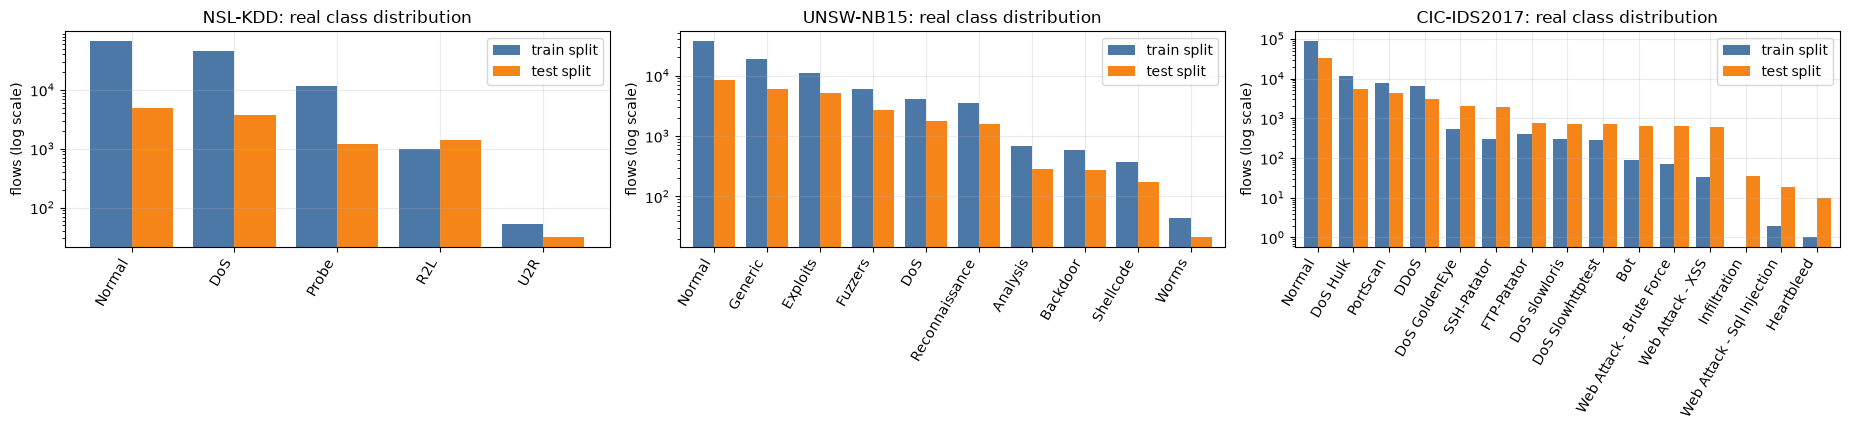

In [7]:
fig, axes = plt.subplots(1, len(DS), figsize=(6.2 * len(DS), 4.4))
axes = np.atleast_1d(axes)
for ax, (name, d) in zip(axes, DS.items()):
    cnt = pd.DataFrame({"train split": pd.Series(d["gtr"]).value_counts(), "test split": pd.Series(d["gte"]).value_counts()}).fillna(0)
    cnt = cnt.loc[cnt.sum(axis=1).sort_values(ascending=False).index]
    cnt.plot.bar(ax=ax, logy=True, width=0.8, color=["#4c78a8", "#f58518"])
    ax.set_title(f"{name}: real class distribution"); ax.set_ylabel("flows (log scale)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=60)
    for lab in ax.get_xticklabels():
        lab.set_ha("right")
plt.tight_layout(); plt.show()

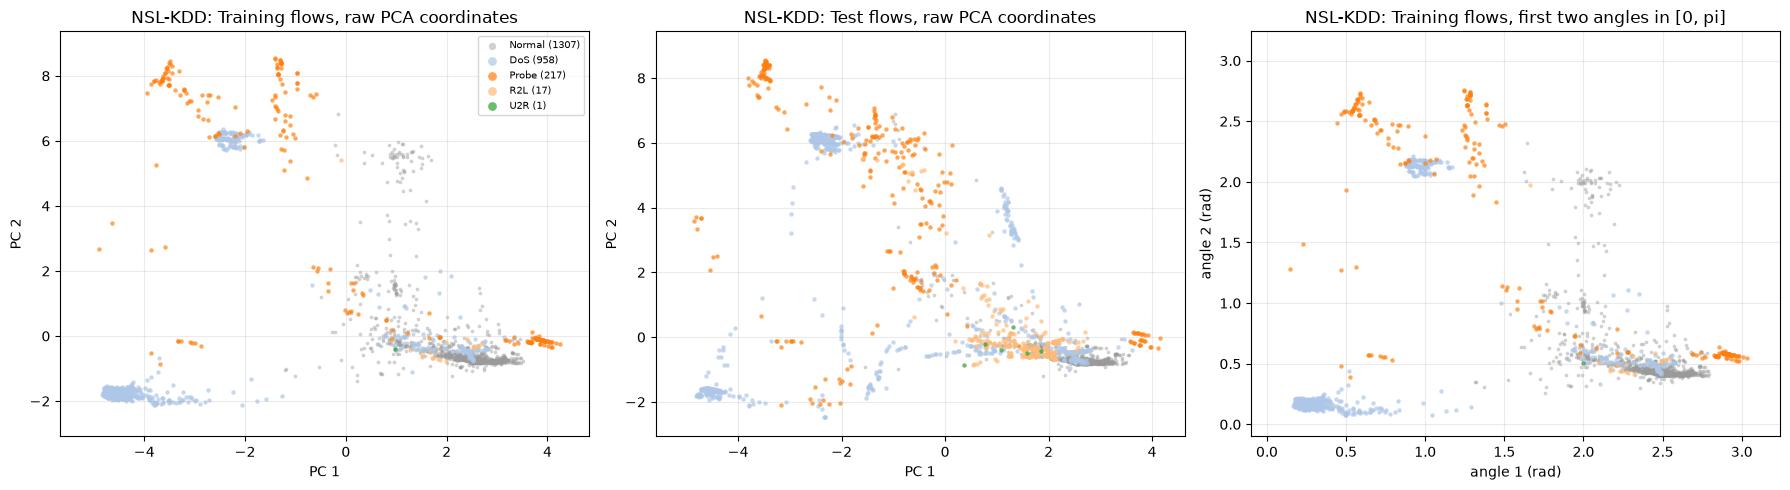

NSL-KDD: PCA explained variance of the two plotted components = [0.08 0.05] (the picture shows only a small part of the 78-190 dimensional geometry)


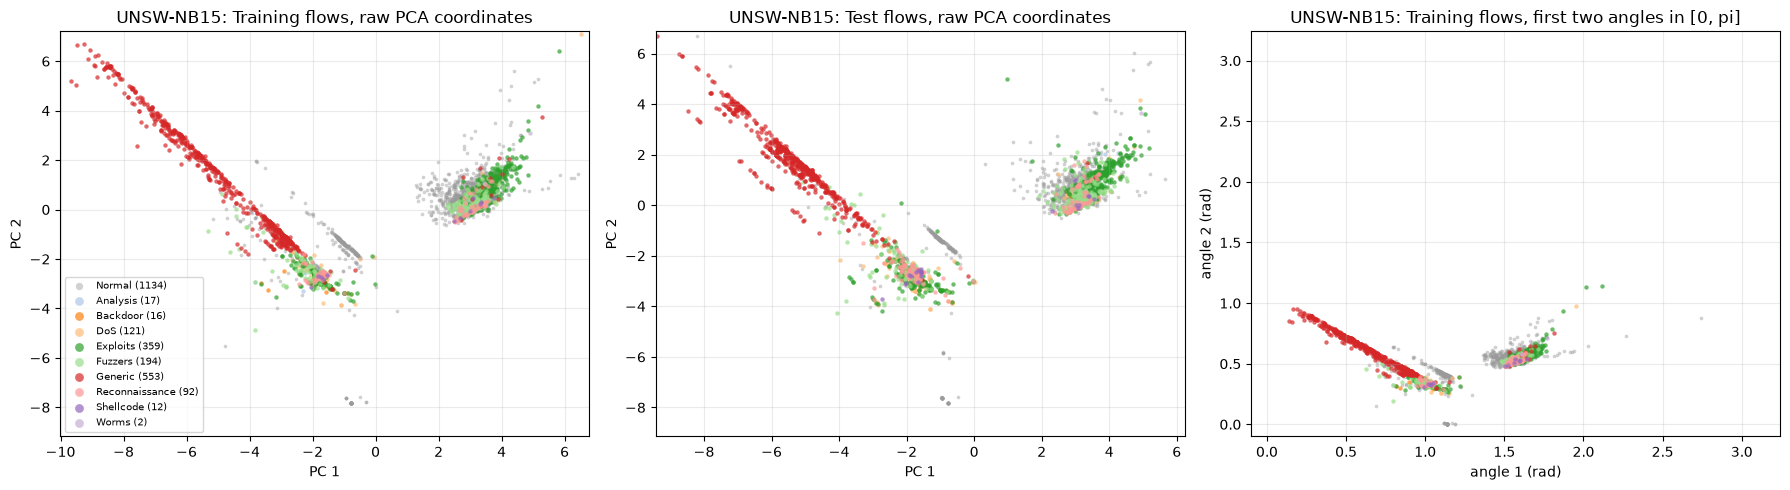

UNSW-NB15: PCA explained variance of the two plotted components = [0.067 0.023] (the picture shows only a small part of the 78-190 dimensional geometry)


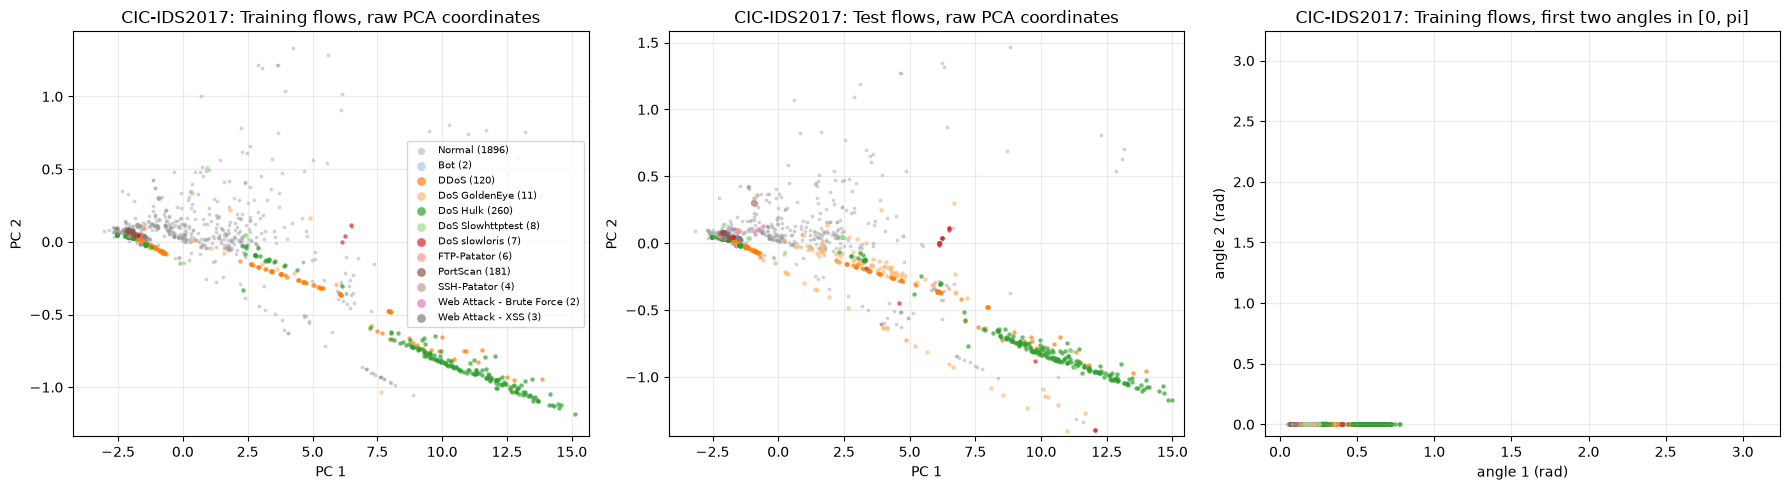

CIC-IDS2017: PCA explained variance of the two plotted components = [0.22  0.155] (the picture shows only a small part of the 78-190 dimensional geometry)


In [8]:
PLOT_N = 2500                      # points drawn per panel (random subset of the real flows)
EXPL = {}                          # remember the fitted 2-D projections for later cells
for name, d in DS.items():
    pca = PCA(n_components=2, random_state=SEED).fit(d["Xtr"])             # fitted on the training split only
    Ptr, Pte = pca.transform(d["Xtr"]), pca.transform(d["Xte"])
    ang = MinMaxScaler((0, np.pi)).fit(Ptr)                                # angle range of the angle-encoding quantum layer
    Atr, Ate = ang.transform(Ptr), np.clip(ang.transform(Pte), 0, np.pi)
    EXPL[name] = (Ptr, Pte, Atr, Ate)
    classes = ["Normal"] + sorted(set(d["gtr"]) | set(d["gte"]) - {"Normal"})
    classes = list(dict.fromkeys(classes))
    pal = {c: ("#9a9a9a" if c == "Normal" else plt.cm.tab20(i % 20)) for i, c in enumerate(classes)}
    rs = np.random.default_rng(SEED)
    itr = rs.choice(len(Ptr), min(PLOT_N, len(Ptr)), replace=False); ite = rs.choice(len(Pte), min(PLOT_N, len(Pte)), replace=False)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    panels = [("Training flows, raw PCA coordinates", Ptr[itr], d["gtr"][itr], "PC 1", "PC 2"),
              ("Test flows, raw PCA coordinates", Pte[ite], d["gte"][ite], "PC 1", "PC 2"),
              ("Training flows, first two angles in [0, pi]", Atr[itr], d["gtr"][itr], "angle 1 (rad)", "angle 2 (rad)")]
    for ax, (title, P, g, xl, yl) in zip(axes, panels):
        for c in classes:                                                   # draw 'Normal' first so attacks stay visible on top
            mk = g == c
            if mk.any():
                ax.scatter(P[mk, 0], P[mk, 1], s=7 if c == "Normal" else 10, alpha=0.45 if c == "Normal" else 0.7, color=pal[c], label=f"{c} ({int(mk.sum())})", linewidths=0)
        ax.set_title(f"{name}: {title}"); ax.set_xlabel(xl); ax.set_ylabel(yl)
        if "angles" in title:
            ax.set_xlim(-0.1, np.pi + 0.1); ax.set_ylim(-0.1, np.pi + 0.1)
        else:                                                               # robust axis limits: a few heavy-tailed flows would squash the picture
            lo, hi = np.percentile(P, [0.5, 99.5], axis=0); pad = 0.1 * (hi - lo)
            ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    axes[0].legend(fontsize=7, markerscale=2, loc="best", ncol=1)
    plt.tight_layout(); plt.show()
    print(f"{name}: PCA explained variance of the two plotted components = {pca.explained_variance_ratio_.round(3)} "
          "(the picture shows only a small part of the 78-190 dimensional geometry)")

## Quantum Circuit Architecture

The only quantum part of every hybrid model is the **QLayer** (paper Section 3.3, Fig. 1): *data encoding -> hardware-efficient variational ansatz -> measurement*. Its four variants are the combinations of two placements and two read-outs:

| Variant | Encoding (classical features -> state) | Ansatz | Read-out |
|---|---|---|---|
| Early / ExpVal | amplitude embedding of a `2^N`-dimensional vector (`N` = 4 qubits -> 16 amplitudes) | `StronglyEntanglingLayers`, 2 layers | `<Z_i>` of each qubit: `N` numbers |
| Early / Probs | amplitude embedding | same | probabilities of the `2^N` basis states: `2^N` numbers |
| Late / ExpVal | angle embedding, one `RX(x_i)` per qubit | same | `<Z_i>` |
| Late / Probs | angle embedding | same | probabilities |

**Paper vs this notebook.** The paper states the *kind* of each block (amplitude or angle embedding, "hardware-efficient ansatz with full entangling layers", Pauli-Z expectation values or computational-basis probabilities) but **not** the number of qubits, the number of layers, nor the gate set. This notebook chooses `N = 4` qubits and `L = 2` layers of PennyLane's `StronglyEntanglingLayers` (a general single-qubit `Rot` on every qubit followed by a ring of CNOTs whose range grows with the layer), i.e. `L x N x 3 = 24` trainable angles. These are marked `# CHOICE:` in the code.

**How the circuit is simulated.** The QLayer sits inside a neural network that is trained on thousands of mini-batches, so calling a PennyLane QNode for every batch would be slow. Instead the notebook builds the *exact* `2^N x 2^N` unitary of the ansatz gate by gate with differentiable PyTorch operations (`build_U`), applies it to the whole batch of encoded states at once, and reads out probabilities or `<Z_i>`. The cells below **prove** that this fast simulator is the circuit of the paper: for all four variants its outputs and its gradients are asserted equal to those of the real PennyLane QNode (`default.qubit`) to numerical precision, and the noisy variant is asserted equal to a QNode that really contains the `RX(eps)` gates. The drawings are produced by `qml.draw_mpl` from those same QNodes.

In [9]:
D = 2 ** N_QUBITS                                   # dimension of the quantum state
# CHOICE: bit i of a basis index j is read with qubit 0 as the most significant bit (PennyLane convention)
_bits = (np.arange(D)[:, None] >> (N_QUBITS - 1 - np.arange(N_QUBITS))[None, :]) & 1
ZSIGN = torch.tensor(1 - 2 * _bits, dtype=torch.float64)       # (D, N): eigenvalue of Pauli-Z_i on basis state j
N_NOISE_GATES = N_LAYERS * N_QUBITS * 3             # one RX(eps) after each Rot (N per layer) and after both wires of each CNOT (2N per layer)

def rot_mats(w):
    """qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi) as 2x2 matrices. w: (..., 3) -> (..., 2, 2)."""
    phi, th, om = w[..., 0], w[..., 1], w[..., 2]
    c, s = torch.cos(th / 2), torch.sin(th / 2)
    e = lambda a: torch.exp(1j * a)
    m00, m01 = e(-(phi + om) / 2) * c, -e((phi - om) / 2) * s
    m10, m11 = e(-(phi - om) / 2) * s, e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

def rx_mats(e):
    """RX(eps) for a vector of angles e: (B,) -> (B, 2, 2)."""
    c, s = torch.cos(e / 2) + 0j, -1j * torch.sin(e / 2)
    return torch.stack([torch.stack([c, s], -1), torch.stack([s, c], -1)], -2)

def cnot_perm(c, t, n=N_QUBITS):
    idx = np.arange(2 ** n); flip = ((idx >> (n - 1 - c)) & 1).astype(bool)
    return torch.tensor(np.where(flip, idx ^ (1 << (n - 1 - t)), idx))

def apply_1q(T, G, q):
    """Left-multiply the (batch of) 2x2 gate(s) G (Bg,2,2) on qubit q of the (batch of) unitaries T (Bu, D, D)."""
    if T.shape[0] != G.shape[0]:
        if T.shape[0] == 1: T = T.expand(G.shape[0], -1, -1)
        else: G = G.expand(T.shape[0], -1, -1)
    X = T.reshape(T.shape[0], 2 ** q, 2, -1)
    return torch.einsum("bij,bajc->baic", G, X).reshape(T.shape[0], D, D)

def build_U(w, eps=None):
    """Unitary of StronglyEntanglingLayers(w) on N_QUBITS wires, shape (1, D, D) -- or (B, D, D) when `eps` (B, N_NOISE_GATES)
    inserts one coherent over-rotation RX(eps_k) after every gate (paper Section 3.7)."""
    T = torch.eye(D, dtype=torch.complex128).unsqueeze(0); R = rot_mats(w); k = 0
    for l in range(N_LAYERS):
        for q in range(N_QUBITS):
            T = apply_1q(T, R[l, q].unsqueeze(0), q)
            if eps is not None:
                T = apply_1q(T, rx_mats(eps[:, k]), q); k += 1
        r = l % (N_QUBITS - 1) + 1                                  # PennyLane default ranges: 1, 2, ...
        for q in range(N_QUBITS):
            t = (q + r) % N_QUBITS
            T = T[:, cnot_perm(q, t), :]                            # CNOT(q -> t) is a permutation of the rows
            if eps is not None:
                T = apply_1q(T, rx_mats(eps[:, k]), q); k += 1      # CHOICE: a CNOT is followed by RX(eps) on both of its qubits
                T = apply_1q(T, rx_mats(eps[:, k]), t); k += 1
    return T

def amplitude_state(x):
    """Amplitude embedding of a real vector of length 2^N, normalised to unit length (qml.AmplitudeEmbedding(normalize=True))."""
    return (x / (x.norm(dim=1, keepdim=True) + 1e-12)).to(torch.complex128)

def angle_state(x):
    """Angle embedding with RX: |psi> = (x)_i [cos(x_i/2)|0> - i sin(x_i/2)|1>] (qml.AngleEmbedding(rotation='X'))."""
    c, s = torch.cos(x / 2), torch.sin(x / 2)
    psi = torch.ones(x.shape[0], 1, dtype=torch.complex128)
    for q in range(N_QUBITS):
        v = torch.stack([c[:, q] + 0j, -1j * s[:, q]], -1)
        psi = (psi[:, :, None] * v[:, None, :]).reshape(x.shape[0], -1)
    return psi

def quantum_layer(x, w, place, meas, eps=None):
    """The QLayer used inside every hybrid model: encode, apply the ansatz, measure. Returns (B, N) <Z_i> or (B, 2^N) probabilities."""
    U = build_U(w, eps)
    psi = amplitude_state(x) if place == "early" else angle_state(x)
    out = psi @ U[0].T if U.shape[0] == 1 else torch.einsum("bij,bj->bi", U, psi)
    p = out.abs() ** 2
    return p @ ZSIGN if meas == "expval" else p

n_ansatz_params = N_LAYERS * N_QUBITS * 3
print(f"simulator ready: {N_QUBITS} qubits, state dimension {D}, ansatz = {N_LAYERS} x StronglyEntanglingLayers, {n_ansatz_params} trainable angles, "
      f"{N_NOISE_GATES} noisy gate slots")

simulator ready: 4 qubits, state dimension 16, ansatz = 2 x StronglyEntanglingLayers, 24 trainable angles, 24 noisy gate slots


In [10]:
dev = qml.device("default.qubit", wires=N_QUBITS)
WIRES = list(range(N_QUBITS))

def make_qnode(place, meas):
    """The real PennyLane circuit of one QLayer variant (this is what is drawn below and what the fast simulator must reproduce)."""
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w):
        if place == "early":
            qml.AmplitudeEmbedding(x, wires=WIRES, normalize=True)          # 2^N classical numbers -> amplitudes
        else:
            qml.AngleEmbedding(x, wires=WIRES, rotation="X")                # N classical numbers -> RX angles
        qml.StronglyEntanglingLayers(w, wires=WIRES)                       # hardware-efficient ansatz, full entangling layers
        if meas == "expval":
            return [qml.expval(qml.PauliZ(i)) for i in WIRES]               # Eq. (6)
        return qml.probs(wires=WIRES)                                       # Eq. (7)
    return circuit

def qnode_out(circuit, x, w):
    o = circuit(x, w)
    return torch.stack(list(o), -1) if isinstance(o, (list, tuple)) else o

def noisy_reference_qnode(place):
    """Reference for the noise study: the same circuit with explicit qml.RX(eps_k) gates inserted after every gate."""
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(x, w, eps):
        if place == "early": qml.AmplitudeEmbedding(x, wires=WIRES, normalize=True)
        else: qml.AngleEmbedding(x, wires=WIRES, rotation="X")
        k = 0
        for l in range(N_LAYERS):
            for q in WIRES:
                qml.Rot(w[l, q, 0], w[l, q, 1], w[l, q, 2], wires=q); qml.RX(eps[k], wires=q); k += 1
            r = l % (N_QUBITS - 1) + 1
            for q in WIRES:
                t = (q + r) % N_QUBITS
                qml.CNOT(wires=[q, t]); qml.RX(eps[k], wires=q); qml.RX(eps[k + 1], wires=t); k += 2
        return qml.probs(wires=WIRES)
    return circuit

QNODES = {(p, m): make_qnode(p, m) for p in ("early", "late") for m in ("expval", "probs")}

# ---------------- equivalence checks: fast simulator == PennyLane QNode (outputs and gradients), four variants + noisy circuit
g = torch.Generator().manual_seed(SEED)
w0 = (torch.rand(N_LAYERS, N_QUBITS, 3, generator=g) * 2 * np.pi).requires_grad_(True)
X_early = torch.randn(6, D, generator=g)                       # arbitrary real 16-vectors (normalised by the embedding)
X_late = torch.rand(6, N_QUBITS, generator=g) * np.pi          # angles in [0, pi]
for (place, meas), circ in QNODES.items():
    X = X_early if place == "early" else X_late
    ref = torch.stack([qnode_out(circ, X[i], w0) for i in range(len(X))])
    fast = quantum_layer(X, w0, place, meas)
    err = (ref - fast).abs().max().item()
    gref = torch.autograd.grad(ref.pow(2).sum(), w0)[0]
    gfast = torch.autograd.grad(quantum_layer(X, w0, place, meas).pow(2).sum(), w0)[0]
    gerr = (gref - gfast).abs().max().item()
    assert err < 1e-9 and gerr < 1e-9, (place, meas, err, gerr)
    print(f"{place:5s}/{meas:6s}: max |QNode - simulator| = {err:.1e}   max |gradient difference| = {gerr:.1e}   -> identical")

for place in ("early", "late"):
    X = X_early if place == "early" else X_late
    ref_c = noisy_reference_qnode(place)
    sig = 0.3
    eps = torch.randn(len(X), N_NOISE_GATES, generator=g) * sig
    ref = torch.stack([ref_c(X[i], w0.detach(), eps[i]) for i in range(len(X))])
    fast = quantum_layer(X, w0.detach(), place, "probs", eps=eps)
    err = (ref - fast).abs().max().item()
    assert err < 1e-9, err
    print(f"noisy circuit ({place}): max |QNode with explicit RX(eps) gates - simulator| = {err:.1e}   -> identical")
print("the zero-noise limit also matches:", torch.allclose(quantum_layer(X_late, w0.detach(), "late", "probs", eps=torch.zeros(len(X_late), N_NOISE_GATES)),
                                                          quantum_layer(X_late, w0.detach(), "late", "probs")))

early/expval: max |QNode - simulator| = 3.2e-13   max |gradient difference| = 1.9e-12   -> identical


early/probs : max |QNode - simulator| = 2.4e-13   max |gradient difference| = 2.7e-13   -> identical


late /expval: max |QNode - simulator| = 2.5e-16   max |gradient difference| = 9.2e-16   -> identical


late /probs : max |QNode - simulator| = 1.9e-16   max |gradient difference| = 3.2e-16   -> identical


noisy circuit (early): max |QNode with explicit RX(eps) gates - simulator| = 1.9e-13   -> identical


noisy circuit (late): max |QNode with explicit RX(eps) gates - simulator| = 4.4e-16   -> identical
the zero-noise limit also matches: True


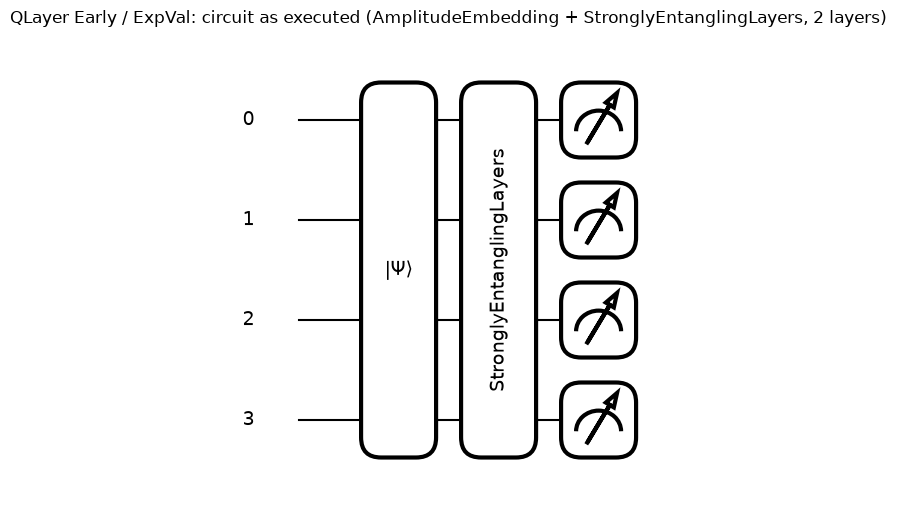

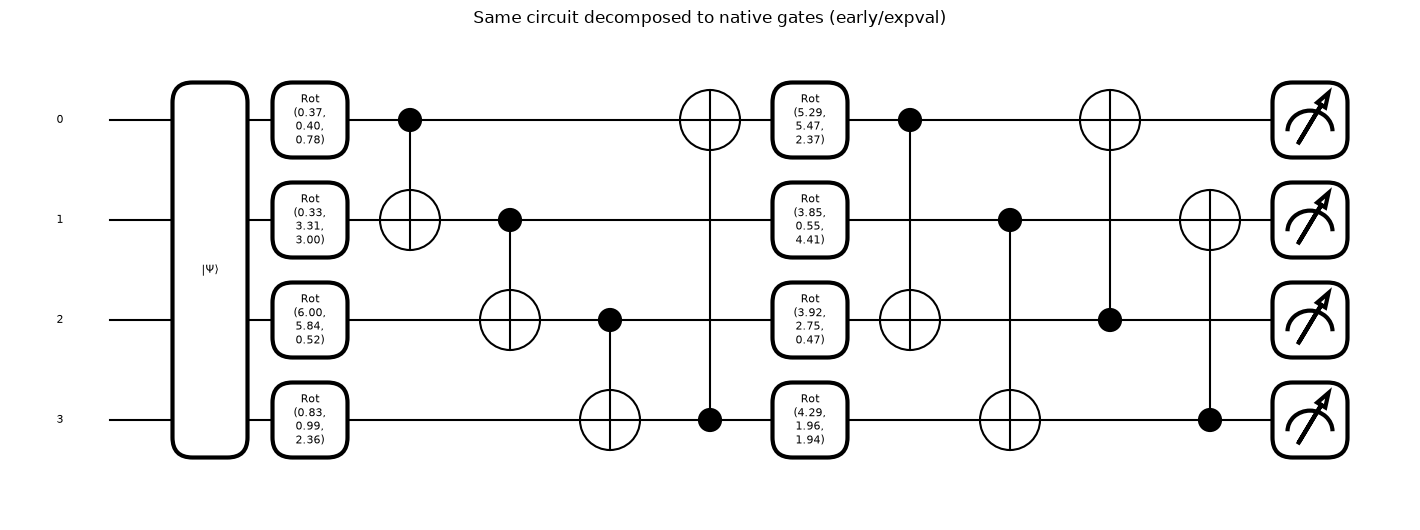

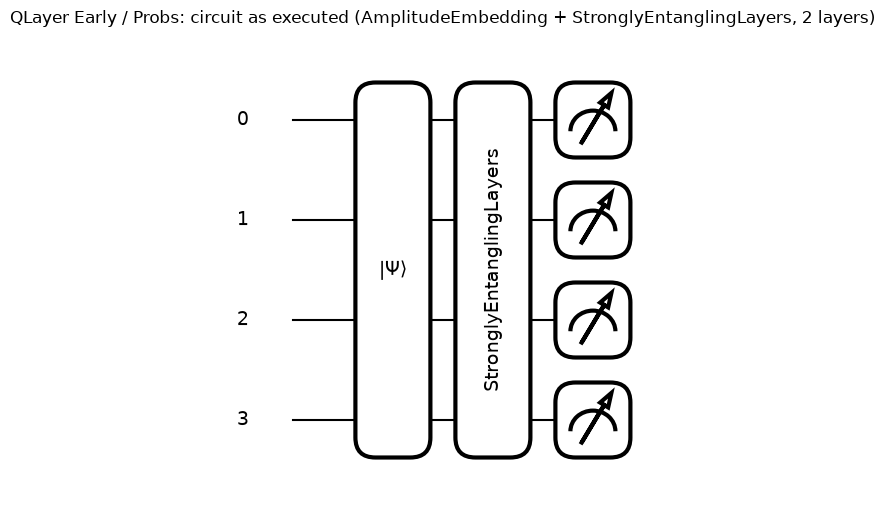

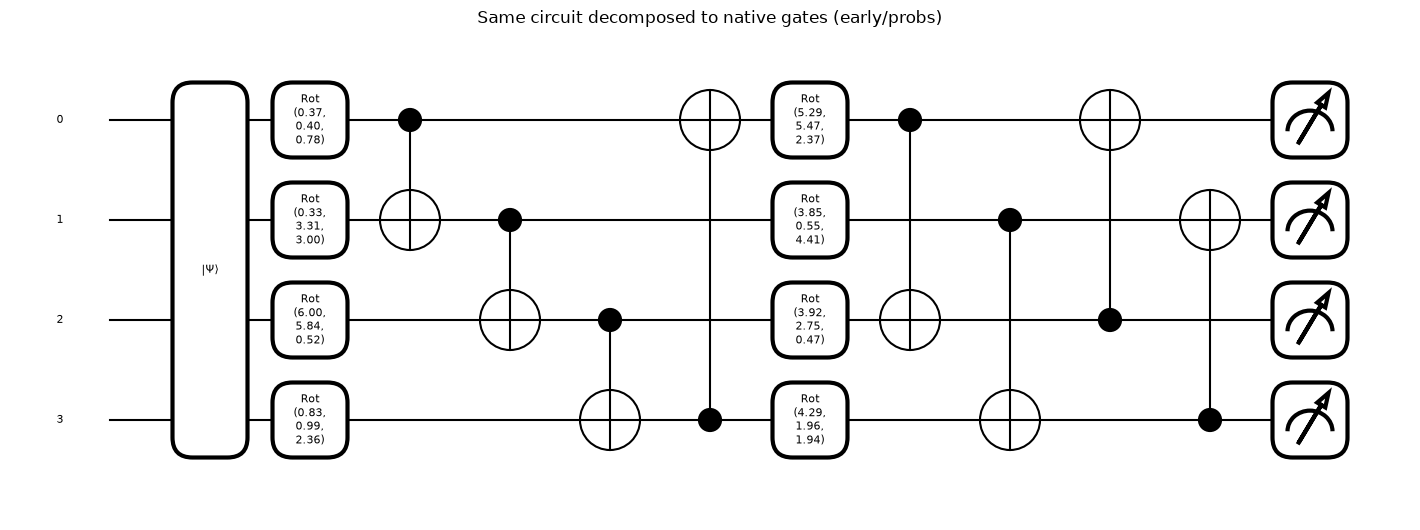

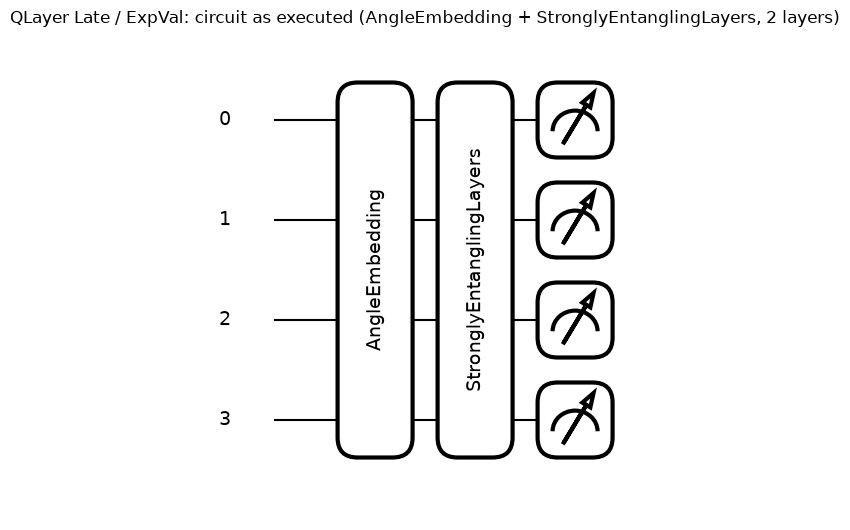

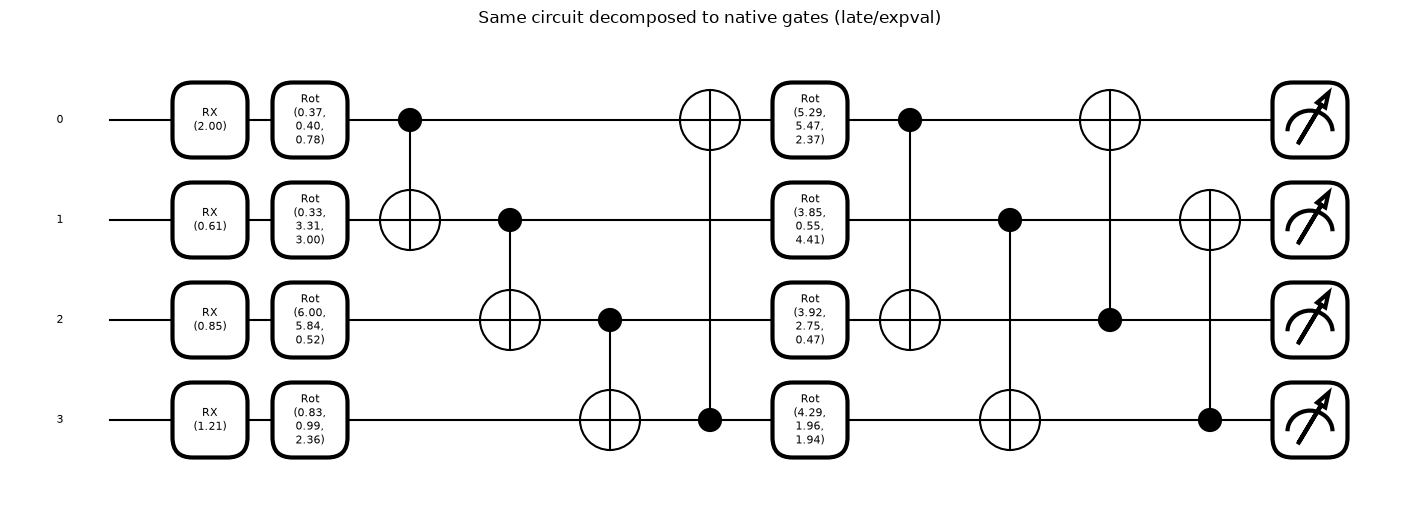

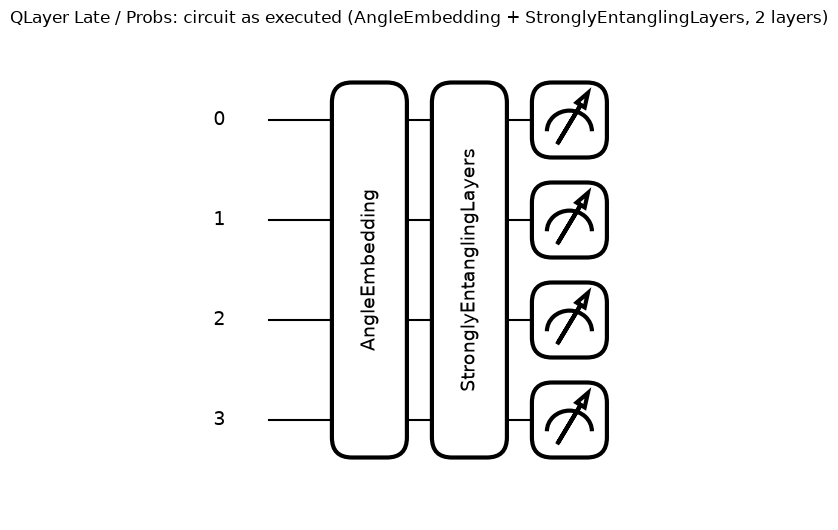

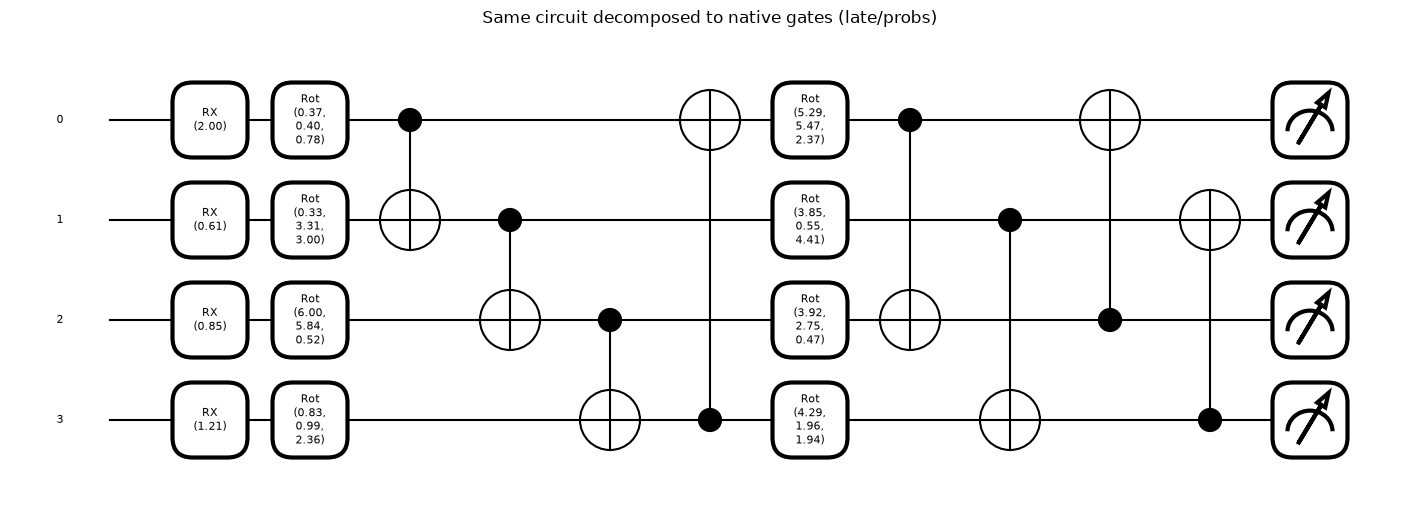

     variant  qubits  depth_templates  depth_native_gates  native_gates  depth_hardware_gates  hardware_gates  trainable_angles  measured_outputs
early/expval       4                2                   9            17                    57              70                24                 4
 early/probs       4                2                   9            17                    57              70                24                16
 late/expval       4                2                   9            20                     9              20                24                 4
  late/probs       4                2                   9            20                     9              20                24                16

'native' = the gates default.qubit runs (it prepares the amplitude state directly, so the embedding counts as one gate); 'hardware' = everything compiled to RX/RY/RZ/Rot/CNOT, where amplitude embedding costs about 2^N controlled rotations.

Assumptions where the paper 

In [11]:
specs_rows = []
x_demo = {"early": X_early[0].detach(), "late": X_late[0].detach()}
w_demo = w0.detach()
for (place, meas), circ in QNODES.items():
    xd = x_demo[place]
    # the circuit as written in the QNode (templates shown as boxes)
    fig, ax = qml.draw_mpl(circ, decimals=2)(xd, w_demo)
    fig.suptitle(f"QLayer {place.capitalize()} / {'ExpVal' if meas == 'expval' else 'Probs'}: circuit as executed "
                 f"({'AmplitudeEmbedding' if place == 'early' else 'AngleEmbedding'} + StronglyEntanglingLayers, {N_LAYERS} layers)", y=1.02)
    plt.show()
    # the same circuit decomposed to the gates the device actually runs
    fig, ax = qml.draw_mpl(circ, level="device", decimals=2, fontsize=8)(xd, w_demo)
    fig.suptitle(f"Same circuit decomposed to native gates ({place}/{meas})", y=1.02)
    plt.show()
    sp = qml.specs(circ, level="device")(xd, w_demo)
    rsrc = sp["resources"]
    try:                                    # depth if the amplitude embedding had to be compiled to one- and two-qubit gates (as on hardware)
        dec = qml.transforms.decompose(circ, gate_set={"RX", "RY", "RZ", "Rot", "CNOT", "GlobalPhase"})
        hw = qml.specs(dec, level="device")(xd, w_demo)["resources"]; hw_depth, hw_gates = hw.depth, hw.num_gates
    except Exception as e:
        hw_depth = hw_gates = None
    specs_rows.append(dict(variant=f"{place}/{meas}", qubits=rsrc.num_allocs, depth_templates=qml.specs(circ)(xd, w_demo)["resources"].depth,
                           depth_native_gates=rsrc.depth, native_gates=rsrc.num_gates, depth_hardware_gates=hw_depth, hardware_gates=hw_gates,
                           trainable_angles=n_ansatz_params,
                           measured_outputs=N_QUBITS if meas == "expval" else D))
print(pd.DataFrame(specs_rows).to_string(index=False))
print("\n'native' = the gates default.qubit runs (it prepares the amplitude state directly, so the embedding counts as one gate); "
      "'hardware' = everything compiled to RX/RY/RZ/Rot/CNOT, where amplitude embedding costs about 2^N controlled rotations.")
print("\nAssumptions where the paper omits circuit details (all marked CHOICE in the code): "
      f"{N_QUBITS} qubits, {N_LAYERS} StronglyEntanglingLayers layers (Rot + CNOT ring, ranges 1, 2), qubit 0 = most significant bit, "
      "AngleEmbedding with RX, exact (shot-free) simulation.")

## 2. The unified autoencoder family (paper Section 3.2-3.3, Eq. 1-5)

`AE` below is one class that covers all 20 architectures of the study. The encoder maps a flow `x` to a latent vector `z` (8 numbers), the decoder maps `z` back to `x_hat`. The loss is the paper's single unified objective

`L_total = L_recon + beta * L_KL + alpha * L_reg`,

where `L_recon` is the mean squared error, `L_KL` the Kullback-Leibler term of a variational autoencoder (switched on by `vae=True`, i.e. `beta > 0`) and `L_reg = ||z - mu_c||^2` the pull of the latent codes towards a learnable centroid (switched on by `latreg=True`, i.e. `alpha > 0`).

For the hybrid versions the QLayer defined above is inserted in the encoder: **early** (a single classical layer, then amplitude embedding of 16 numbers) or **late** (classical layers first, then 4 angles). Its `N` expectation values or `2^N` probabilities go through a small classical layer into the latent code. In the PyTorch graph the QLayer is the exact simulator verified against the PennyLane circuits above, so gradients flow through the quantum circuit by back-propagation and its 24 angles are trained together with the network weights (the paper does the same with JAX).

In [12]:
class QLayer(nn.Module):
    """Trainable wrapper around `quantum_layer`: the 24 ansatz angles are ordinary PyTorch parameters (paper: trained jointly by backpropagation)."""
    def __init__(self, place, meas):
        super().__init__(); self.place, self.meas = place, meas
        self.w = nn.Parameter(torch.rand(N_LAYERS, N_QUBITS, 3) * 2 * np.pi)       # CHOICE: uniform [0, 2 pi] initial angles
    def forward(self, x, eps=None):
        return quantum_layer(x, self.w, self.place, self.meas, eps)

class AE(nn.Module):
    """Unified autoencoder of paper Fig. 1 / Eq. (5).  place=None -> classical encoder; place in {early, late} -> hybrid encoder.
       vae=True adds the mean/log-variance head (beta > 0); latreg=True adds the learnable centroid mu_c (alpha > 0)."""
    def __init__(self, d, place=None, meas=None, vae=False, latreg=False):
        super().__init__(); self.vae, self.place, self.meas = vae, place, meas
        if place is None:                                                          # classical: d -> 64 -> 32
            self.enc = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU()); width = 32
        else:
            if place == "early":                                                   # CHOICE: one linear projection to 2^N amplitudes, QLayer first
                self.enc = nn.Sequential(nn.Linear(d, D))
            else:                                                                  # CHOICE: classical layers first, then N angles in (-pi, pi)
                self.enc = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, N_QUBITS), nn.Tanh())
            self.ql = QLayer(place, meas)
            self.post = nn.Sequential(nn.Linear(N_QUBITS if meas == "expval" else D, 32), nn.ReLU()); width = 32   # CHOICE: classical layer after the QLayer
        self.mu = nn.Linear(width, LATENT); self.lv = nn.Linear(width, LATENT) if vae else None
        self.dec = nn.Sequential(nn.Linear(LATENT, 32), nn.ReLU(), nn.Linear(32, 64), nn.ReLU(), nn.Linear(64, d))
        self.c = nn.Parameter(torch.zeros(LATENT)) if latreg else None
    def encode(self, x, eps=None):
        h = self.enc(x)
        if self.place is not None:
            h = self.post(self.ql(h * np.pi if self.place == "late" else h, eps))
        return h
    def forward(self, x, eps=None):
        h = self.encode(x, eps); mu = self.mu(h)
        if self.vae:
            lv = self.lv(h); z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv) if self.training else mu
        else:
            lv, z = None, mu
        return self.dec(z), mu, lv, z

def total_loss(m, x):
    """L_total = L_recon + beta * L_KL + alpha * L_reg   (paper Eq. 5); L_recon is the per-feature mean squared error."""
    xh, mu, lv, z = m(x); loss = ((x - xh) ** 2).mean()
    if m.vae:
        loss = loss + BETA * (-0.5 * (1 + lv - mu ** 2 - lv.exp()).sum(1).mean())
    if m.c is not None:
        loss = loss + ALPHA * ((z - m.c) ** 2).sum(1).mean()
    return loss

def train_ae(m, X, seed, epochs, patience):
    """Adam (lr 1e-3, batch 256), early stopping on a validation loss (10 % of the normal training flows), best weights restored."""
    g = torch.Generator().manual_seed(seed); idx = torch.randperm(len(X), generator=g); nv = max(len(X) // 10, BATCH)
    Xv, Xt = X[idx[:nv]], X[idx[nv:]]; opt = torch.optim.Adam(m.parameters(), lr=LR); best, bad, state, hist = 1e18, 0, None, []
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xt), generator=g); tl = 0.0
        for i in range(0, len(Xt), BATCH):
            xb = Xt[perm[i:i + BATCH]]; opt.zero_grad(); l = total_loss(m, xb); l.backward(); opt.step(); tl += l.item() * len(xb)
        m.eval()
        with torch.no_grad():
            vl = total_loss(m, Xv).item()
        hist.append((tl / len(Xt), vl))
        if vl < best - 1e-6: best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(state); m.eval(); return hist

@torch.no_grad()
def recon_and_latent(m, X, eps_sigma=None, chunk=8192, gen=None):
    """Per-flow reconstruction error (mean squared error over the features) and latent mean; optional coherent gate noise (per flow)."""
    errs, lats = [], []
    for i in range(0, len(X), chunk):
        xb = X[i:i + chunk]
        eps = None if not eps_sigma else torch.randn(len(xb), N_NOISE_GATES, generator=gen) * eps_sigma
        xh, mu, _, _ = m(xb, eps); errs.append(((xb - xh) ** 2).mean(1)); lats.append(mu)
    return torch.cat(errs).numpy(), torch.cat(lats).numpy()

# ---- the 4 classical + 16 hybrid configurations of the design space
CFGS = [(None, None, vae, reg) for vae in (False, True) for reg in (False, True)] + \
       [(p, me, vae, reg) for p in ("early", "late") for me in ("expval", "probs") for vae in (False, True) for reg in (False, True)]

def cfg_name(c):
    p, me, vae, reg = c
    base = "Classical" if p is None else f"HQCAE-{p.capitalize()}-{'ExpVal' if me == 'expval' else 'Probs'}"
    return f"{base} ({'VAE' if vae else 'AE'}{', LatReg' if reg else ''})"

print(f"{len(CFGS)} configurations ({sum(c[0] is None for c in CFGS)} classical + {sum(c[0] is not None for c in CFGS)} hybrid), each scored with 2 detectors")
for c in (CFGS[0], CFGS[4], CFGS[8], CFGS[12], CFGS[16]):
    n_par = sum(p.numel() for p in AE(100, *c).parameters())
    print(f"  {cfg_name(c):42s} trainable parameters for 100 input features: {n_par}"
          + ("" if c[0] is None else f"  (of which {n_ansatz_params} quantum angles)"))

20 configurations (4 classical + 16 hybrid), each scored with 2 detectors


  Classical (AE)                             trainable parameters for 100 input features: 17708
  HQCAE-Early-ExpVal (AE)                    trainable parameters for 100 input features: 10964  (of which 24 quantum angles)
  HQCAE-Early-Probs (AE)                     trainable parameters for 100 input features: 11348  (of which 24 quantum angles)
  HQCAE-Late-ExpVal (AE)                     trainable parameters for 100 input features: 18024  (of which 24 quantum angles)
  HQCAE-Late-Probs (AE)                      trainable parameters for 100 input features: 18408  (of which 24 quantum angles)


## 3. Training the whole design space

For every dataset and every seed the notebook trains the 4 classical and the 16 hybrid autoencoders on the (capped) normal training flows, with early stopping on a validation split of those flows. Each trained model is scored by **two** detectors on the test flows: the reconstruction error (the threshold `tau` is the 95th percentile of the error on the normal training flows and is used for F1/TPR/FPR only) and an Isolation Forest fitted on the latent codes of the normal training flows. The AUROC of every (dataset, seed, configuration, detector) combination is stored; all later tables are computed from these run-level numbers. The trained weights are kept in memory for the leave-one-attack-out study, the latent-space picture and the noise study.

In [13]:
RESULTS, MODELS, HISTORY = [], {}, {}      # run-level AUROCs, trained weights, training curves

def normal_subset(d, seed):
    """The normal training flows one run sees: a random subset of size normal_cap (paper: all normal training flows)."""
    Xn = d["Xtr"][d["ytr"] == 0]
    idx = np.random.default_rng(seed).permutation(len(Xn))[:B["normal_cap"]]
    return Xn[idx]

def detector_scores(m, Xn_t, Xte_t, seed, detector):
    """Anomaly scores of the test flows: reconstruction error, or an Isolation Forest fitted on the latent codes of the normal training flows only."""
    if detector == "recon":
        return recon_and_latent(m, Xte_t)[0]
    _, z_tr = recon_and_latent(m, Xn_t[:B["ifor_cap"]]); _, z_te = recon_and_latent(m, Xte_t)
    forest = IsolationForest(n_estimators=100, random_state=seed).fit(z_tr)
    return -forest.score_samples(z_te)                                   # larger = more anomalous

def run_grid(name):
    d = DS[name]; uni = d["uni_te"]; Xte_t = torch.tensor(d["Xte"][uni]); yte = d["yte"][uni]; t_ds = time.time()
    for seed in SEEDS:
        Xn = normal_subset(d, seed); Xn_t = torch.tensor(Xn); t_seed = time.time()
        for ci, cfg in enumerate(CFGS):
            torch.manual_seed(seed * 1000 + ci); t0 = time.time()
            m = AE(d["Xtr"].shape[1], *cfg)
            hist = train_ae(m, Xn_t, seed * 1000 + ci, B["epochs"], B["patience"])
            MODELS[(name, cfg, seed)] = {k: v.clone() for k, v in m.state_dict().items()}; HISTORY[(name, cfg, seed)] = hist
            err_tr, _ = recon_and_latent(m, Xn_t)
            tau = np.percentile(err_tr, THRESHOLD_PERCENTILE)               # paper Section 3.4: 95th percentile on the normal training flows
            for det in ("recon", "iforest"):
                s = detector_scores(m, Xn_t, Xte_t, seed, det)
                row = dict(dataset=name, seed=seed, cfg=cfg, model=cfg_name(cfg), family="Classical" if cfg[0] is None else "HQC",
                           place=cfg[0], meas=cfg[1], vae=cfg[2], reg=cfg[3], detector=det, auroc=roc_auc_score(yte, s), epochs=len(hist),
                           seconds=time.time() - t0)
                if det == "recon":
                    pred = (s > tau).astype(int)
                    row.update(f1_tau=f1_score(yte, pred), tpr_tau=pred[yte == 1].mean(), fpr_tau=pred[yte == 0].mean())
                RESULTS.append(row)
        print(f"  {name} seed {seed}: 20 configurations trained in {time.time() - t_seed:.0f} s", flush=True)
    print(f"{name}: grid finished in {time.time() - t_ds:.0f} s")

In [14]:
T_GRID = time.time()
for _name in USE_DATASETS:
    run_grid(_name)
res = pd.DataFrame(RESULTS)
print(f"\ntotal grid time {(time.time() - T_GRID) / 60:.1f} min, {len(res)} run-level AUROCs ({res.groupby(['dataset', 'detector']).size().to_dict()})")
res.groupby(["dataset", "family", "detector"])["auroc"].agg(["mean", "std", "min", "max"]).round(4)

  NSL-KDD seed 42: 20 configurations trained in 157 s


  NSL-KDD seed 43: 20 configurations trained in 181 s


NSL-KDD: grid finished in 339 s


  UNSW-NB15 seed 42: 20 configurations trained in 145 s


  UNSW-NB15 seed 43: 20 configurations trained in 246 s


UNSW-NB15: grid finished in 392 s


  CIC-IDS2017 seed 42: 20 configurations trained in 286 s


  CIC-IDS2017 seed 43: 20 configurations trained in 117 s


CIC-IDS2017: grid finished in 406 s

total grid time 19.0 min, 240 run-level AUROCs ({('CIC-IDS2017', 'iforest'): 40, ('CIC-IDS2017', 'recon'): 40, ('NSL-KDD', 'iforest'): 40, ('NSL-KDD', 'recon'): 40, ('UNSW-NB15', 'iforest'): 40, ('UNSW-NB15', 'recon'): 40})


mean     std     min     max
dataset     family    detector                                
CIC-IDS2017 Classical iforest   0.7225  0.0298  0.6922  0.7731
                      recon     0.7147  0.0179  0.6901  0.7427
            HQC       iforest   0.7232  0.0710  0.5707  0.8527
                      recon     0.7050  0.0107  0.6900  0.7399
NSL-KDD     Classical iforest   0.9126  0.0372  0.8427  0.9555
                      recon     0.9218  0.0054  0.9137  0.9293
            HQC       iforest   0.9104  0.0337  0.8100  0.9537
                      recon     0.9219  0.0035  0.9155  0.9262
UNSW-NB15   Classical iforest   0.6937  0.0497  0.6150  0.7719
                      recon     0.6322  0.0210  0.5987  0.6574
            HQC       iforest   0.7056  0.0651  0.5729  0.8277
                      recon     0.6481  0.0154  0.6262  0.6970

## 4. Best classical versus best hybrid autoencoder (paper Table 2, Fig. 2, Observation 1)

For each dataset the configuration (architecture x detector) with the highest mean AUROC over the seeds is chosen separately for the classical and the hybrid family, and the two are compared with a paired t-test over the matched seeds (99 % confidence interval, Cohen's `d_z`, significance level 0.01). As in the paper the "best" configuration is selected on the test AUROC, so both numbers are optimistic; the comparison between them is still informative. With fewer than three seeds a t-test is not possible and the table says so. The violin plot then shows the AUROC of **all** configurations, which is what the paper's Observation 1 (hybrid models are more sensitive to architecture choices) is about.

In [15]:
def paired_stats(a, b, alpha=0.01):
    """Paired t-test on run-level AUROCs (matched seeds). Returns mean difference (a-b), 99 % CI, p, Cohen's d_z and the significance flag."""
    a, b = np.asarray(a, float), np.asarray(b, float); dlt = a - b; n = len(dlt)
    if n < 3 or dlt.std(ddof=1) == 0:
        return dict(delta=dlt.mean(), ci_lo=np.nan, ci_hi=np.nan, p=np.nan, dz=np.nan, sig=None, n=n)
    sd = dlt.std(ddof=1); tcrit = stats.t.ppf(1 - alpha / 2, n - 1); se = sd / np.sqrt(n)
    p = stats.ttest_rel(a, b).pvalue
    return dict(delta=dlt.mean(), ci_lo=dlt.mean() - tcrit * se, ci_hi=dlt.mean() + tcrit * se, p=p, dz=dlt.mean() / sd, sig=bool(p < alpha), n=n)

BEST = {}
rows = []
for name in USE_DATASETS:
    for fam in ("Classical", "HQC"):
        sub = res[(res.dataset == name) & (res.family == fam)]
        g = sub.groupby(["cfg", "detector"])["auroc"].mean()
        BEST[(name, fam)] = g.idxmax()
    (cc, cdet), (hc, hdet) = BEST[(name, "Classical")], BEST[(name, "HQC")]
    ca = res[(res.dataset == name) & (res.cfg == cc) & (res.detector == cdet)].sort_values("seed")["auroc"].values
    ha = res[(res.dataset == name) & (res.cfg == hc) & (res.detector == hdet)].sort_values("seed")["auroc"].values
    st = paired_stats(ha, ca)
    rows.append(dict(dataset=name, classical_best=f"{cfg_name(cc)} [{cdet}]", classical_auroc=f"{ca.mean():.4f} +- {ca.std(ddof=1) if len(ca) > 1 else 0:.4f}",
                     hqc_best=f"{cfg_name(hc)} [{hdet}]", hqc_auroc=f"{ha.mean():.4f} +- {ha.std(ddof=1) if len(ha) > 1 else 0:.4f}",
                     d_auroc=st["delta"], ci99=f"[{st['ci_lo']:.4f}, {st['ci_hi']:.4f}]", p=st["p"], dz=st["dz"], significant=st["sig"],
                     _c=ca.mean(), _h=ha.mean()))
T2 = pd.DataFrame(rows)
print("Table 2 analogue: best classical vs best hybrid autoencoder per dataset (mean +- std over", len(SEEDS), "seeds; delta = HQC - classical;")
print("                  the 'best' configuration is picked by its mean test AUROC, exactly the selection rule of the paper, so both columns are optimistic)")
T2.drop(columns=["_c", "_h"]).round(4)

Table 2 analogue: best classical vs best hybrid autoencoder per dataset (mean +- std over 2 seeds; delta = HQC - classical;
                  the 'best' configuration is picked by its mean test AUROC, exactly the selection rule of the paper, so both columns are optimistic)


,dataset,classical_best,classical_auroc,hqc_best,hqc_auroc,d_auroc,ci99,p,dz,significant
0,NSL-KDD,"Classical (VAE, LatReg) [iforest]",0.9509 +- 0.0066,"HQCAE-Late-Probs (VAE, LatReg) [iforest]",0.9504 +- 0.0003,-0.0005,"[nan, nan]",NaN,NaN,None
1,UNSW-NB15,"Classical (AE, LatReg) [iforest]",0.7512 +- 0.0292,"HQCAE-Late-Probs (VAE, LatReg) [iforest]",0.8056 +- 0.0191,0.0544,"[nan, nan]",NaN,NaN,None
2,CIC-IDS2017,"Classical (AE, LatReg) [iforest]",0.7473 +- 0.0366,HQCAE-Late-Probs (AE) [iforest],0.8499 +- 0.0038,0.1027,"[nan, nan]",NaN,NaN,None


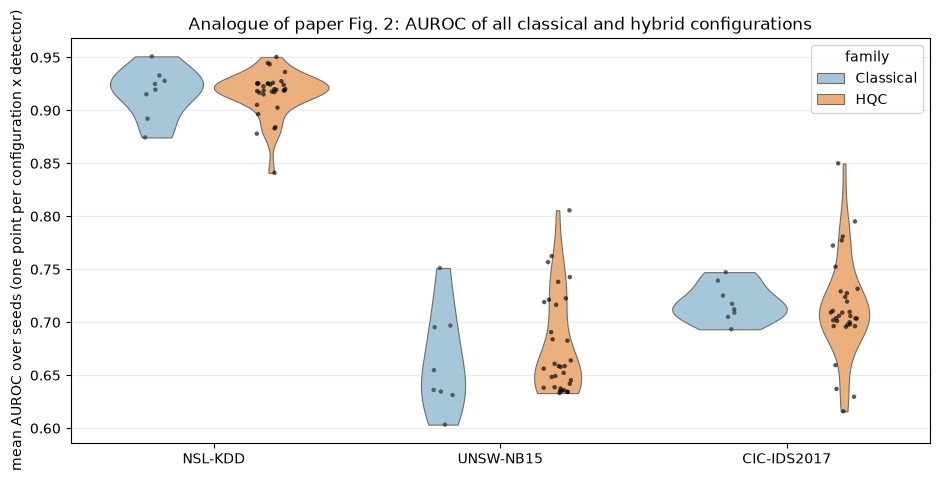

                       count  median     std     min     max
dataset     family                                          
CIC-IDS2017 Classical      8  0.7148  0.0179  0.6934  0.7473
            HQC           32  0.7060  0.0466  0.6159  0.8499
NSL-KDD     Classical      8  0.9222  0.0240  0.8744  0.9509
            HQC           32  0.9197  0.0212  0.8410  0.9504
UNSW-NB15   Classical      8  0.6455  0.0480  0.6034  0.7512
            HQC           32  0.6582  0.0467  0.6332  0.8056


In [16]:
cfg_mean = res.groupby(["dataset", "family", "model", "detector"])["auroc"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9.5, 4.8))
sns.violinplot(data=cfg_mean, x="dataset", y="auroc", hue="family", split=False, inner=None, cut=0, linewidth=0.8, palette={"Classical": "#9ecae1", "HQC": "#fdae6b"}, ax=ax, order=USE_DATASETS)
sns.stripplot(data=cfg_mean, x="dataset", y="auroc", hue="family", dodge=True, size=3.2, color="k", alpha=0.65, ax=ax, order=USE_DATASETS, legend=False)
ax.set_ylabel("mean AUROC over seeds (one point per configuration x detector)"); ax.set_xlabel("")
ax.set_title("Analogue of paper Fig. 2: AUROC of all classical and hybrid configurations")
plt.tight_layout(); plt.show()
print(cfg_mean.groupby(["dataset", "family"])["auroc"].agg(["count", "median", "std", "min", "max"]).round(4))

## 5. Supervised references and the zero-day (leave-one-attack-out) protocol (paper Section 3.5 and 4.2, Table 4, Fig. 3)

**Full test set.** The supervised reference is the classical encoder plus one sigmoid unit, trained with binary cross-entropy on *all* labelled attack classes: an upper bound when every attack is known. A random forest, a PCA reconstruction-error detector and an Isolation Forest on the raw inputs are added as simple classical references on the same standardised inputs.

**LOAO (zero-day simulation).** For every attack class in turn, the supervised network is retrained without that class and tested on the normal test flows plus the held-out class only. The unsupervised autoencoders never see attacks, so the same trained models (the best classical and the best hybrid configuration of the previous section) are simply scored on the same per-class test sets. As in the paper, the reported LOAO number is the mean over the held-out attack classes and the "std" is the spread **across those classes** (not across seeds); a small spread means that the detector is equally good on every kind of attack.

In [17]:
class SupNet(nn.Module):
    """Supervised reference of paper Section 3.5: the classical encoder (same layers as the classical autoencoder) + one sigmoid output neuron."""
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, LATENT), nn.Linear(LATENT, 1))
    def forward(self, x):
        return self.enc(x).squeeze(-1)                               # logit; sigmoid is inside BCEWithLogitsLoss / the AUROC ranking

def train_sup(X, y, seed, epochs, patience):
    g = torch.Generator().manual_seed(seed); m = SupNet(X.shape[1]); idx = torch.randperm(len(X), generator=g); nv = max(len(X) // 10, BATCH)
    Xv, yv, Xt, yt = X[idx[:nv]], y[idx[:nv]], X[idx[nv:]], y[idx[nv:]]
    opt = torch.optim.Adam(m.parameters(), lr=LR); lossf = nn.BCEWithLogitsLoss(); best, bad, state = 1e18, 0, None
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xt), generator=g)
        for i in range(0, len(Xt), BATCH):
            b = perm[i:i + BATCH]; opt.zero_grad(); l = lossf(m(Xt[b]), yt[b]); l.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = lossf(m(Xv), yv).item()
        if vl < best - 1e-6: best, bad, state = vl, 0, {k: v.clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    m.load_state_dict(state); m.eval(); return m

def sup_train_rows(d, seed, exclude=None):
    """Labelled training flows (optionally without the held-out attack class), capped at sup_cap random rows."""
    keep = np.arange(len(d["gtr"])) if exclude is None else np.where(d["gtr"] != exclude)[0]
    keep = np.random.default_rng(seed).permutation(keep)[:B["sup_cap"]]
    return torch.tensor(d["Xtr"][keep]), torch.tensor(d["ytr"][keep], dtype=torch.float64)

SUP_ROWS = []
for name in USE_DATASETS:
    d = DS[name]; uni = d["uni_te"]; Xte_u, yte_u = d["Xte"][uni], d["yte"][uni]; Xte_t = torch.tensor(Xte_u); t0 = time.time()
    for seed in SEEDS:
        Xs, ys = sup_train_rows(d, seed)
        m = train_sup(Xs, ys, seed, B["sup_epochs"], B["patience"])
        with torch.no_grad():
            SUP_ROWS.append(dict(dataset=name, seed=seed, model="Supervised NN (classical encoder)", auroc=roc_auc_score(yte_u, m(Xte_t).numpy())))
        rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=2).fit(Xs.numpy(), ys.numpy().astype(int))
        SUP_ROWS.append(dict(dataset=name, seed=seed, model="Supervised RandomForest", auroc=roc_auc_score(yte_u, rf.predict_proba(Xte_u)[:, 1])))
        # unsupervised classical references that use the same normal flows as the autoencoders
        Xn = normal_subset(d, seed)
        pca = PCA(n_components=LATENT, random_state=seed).fit(Xn)
        rec = ((Xte_u - pca.inverse_transform(pca.transform(Xte_u))) ** 2).mean(1)
        SUP_ROWS.append(dict(dataset=name, seed=seed, model=f"PCA({LATENT}) reconstruction error", auroc=roc_auc_score(yte_u, rec)))
        iso = IsolationForest(n_estimators=100, random_state=seed).fit(Xn[:B["ifor_cap"]])
        SUP_ROWS.append(dict(dataset=name, seed=seed, model="Isolation Forest on standardised inputs", auroc=roc_auc_score(yte_u, -iso.score_samples(Xte_u))))
    print(f"{name}: supervised and classical reference models done ({time.time() - t0:.0f} s)", flush=True)
sup = pd.DataFrame(SUP_ROWS)
ref_tab = sup.groupby(["model", "dataset"])["auroc"].agg(["mean", "std"]).round(4).unstack("dataset")
ref_tab

NSL-KDD: supervised and classical reference models done (12 s)


UNSW-NB15: supervised and classical reference models done (16 s)


CIC-IDS2017: supervised and classical reference models done (26 s)


mean                    \
dataset                                 CIC-IDS2017 NSL-KDD UNSW-NB15   
model                                                                   
Isolation Forest on standardised inputs      0.7272  0.9398    0.7224   
PCA(8) reconstruction error                  0.8140  0.9482    0.7650   
Supervised NN (classical encoder)            0.9765  0.8903    0.9752   
Supervised RandomForest                      0.9988  0.9531    0.9851   

                                                std                    
dataset                                 CIC-IDS2017 NSL-KDD UNSW-NB15  
model                                                                  
Isolation Forest on standardised inputs      0.0030  0.0067    0.0165  
PCA(8) reconstruction error                  0.0077  0.0026    0.0123  
Supervised NN (classical encoder)            0.0025  0.0203    0.0021  
Supervised RandomForest                      0.0007  0.0038    0.0006

In [18]:
def loao_classes(d):
    cnt = pd.Series(d["gte"]).value_counts()
    return [c for c in cnt.index if c != "Normal" and cnt[c] >= B["min_class_rows"]]

def load_model(name, cfg, seed):
    m = AE(DS[name]["Xtr"].shape[1], *cfg); m.load_state_dict(MODELS[(name, cfg, seed)]); m.eval(); return m

LOAO = []                                   # rows: dataset, model, class, seed, auroc
for name in USE_DATASETS:
    d = DS[name]; gte, Xte = d["gte"], d["Xte"]; classes = loao_classes(d); t0 = time.time()
    normal_idx = np.where((gte == "Normal") & d["uni_te"])[0]
    print(f"{name}: held-out attack classes with >= {B['min_class_rows']} test flows: {classes}")
    # ---- unsupervised models: nothing to retrain, the attack class was never seen (all training used normal flows only)
    for fam in ("Classical", "HQC"):
        cfg, det = BEST[(name, fam)]
        for seed in SEEDS:
            m = load_model(name, cfg, seed)
            Xn_t = torch.tensor(normal_subset(d, seed))
            for c in classes:
                idx = np.concatenate([normal_idx, np.where(gte == c)[0]]); y = np.r_[np.zeros(len(normal_idx)), np.ones((gte == c).sum())]
                s = detector_scores(m, Xn_t, torch.tensor(Xte[idx]), seed, det)
                LOAO.append(dict(dataset=name, model=f"Unsupervised ({fam})", cls=c, seed=seed, auroc=roc_auc_score(y, s)))
    # ---- supervised model: retrained without the held-out attack class (zero-day simulation)
    for seed in SEEDS[:B["loao_seeds"]]:
        for c in classes:
            Xs, ys = sup_train_rows(d, seed, exclude=c)
            m = train_sup(Xs, ys, seed, B["sup_epochs"], B["patience"])
            idx = np.concatenate([normal_idx, np.where(gte == c)[0]]); y = np.r_[np.zeros(len(normal_idx)), np.ones((gte == c).sum())]
            with torch.no_grad():
                LOAO.append(dict(dataset=name, model="Supervised (Classical)", cls=c, seed=seed, auroc=roc_auc_score(y, m(torch.tensor(Xte[idx])).numpy())))
    print(f"  {name}: leave-one-attack-out finished in {time.time() - t0:.0f} s", flush=True)
loao = pd.DataFrame(LOAO)
per_class = loao.groupby(["dataset", "model", "cls"])["auroc"].mean().reset_index()     # average the seeds first, then look across held-out classes
T4_loao = per_class.groupby(["dataset", "model"])["auroc"].agg(["mean", "std", "count"]).round(4)
T4_loao

NSL-KDD: held-out attack classes with >= 20 test flows: ['DoS', 'R2L', 'Probe', 'U2R']


  NSL-KDD: leave-one-attack-out finished in 23 s


UNSW-NB15: held-out attack classes with >= 20 test flows: ['Generic', 'Exploits', 'Fuzzers', 'DoS', 'Reconnaissance', 'Analysis', 'Backdoor', 'Shellcode', 'Worms']


  UNSW-NB15: leave-one-attack-out finished in 54 s


CIC-IDS2017: held-out attack classes with >= 20 test flows: ['DoS Hulk', 'PortScan', 'DDoS', 'DoS GoldenEye', 'SSH-Patator', 'FTP-Patator', 'DoS slowloris', 'DoS Slowhttptest', 'Bot', 'Web Attack - Brute Force', 'Web Attack - XSS', 'Infiltration']


  CIC-IDS2017: leave-one-attack-out finished in 173 s


mean     std  count
dataset     model                                          
CIC-IDS2017 Supervised (Classical)    0.7001  0.2166     12
            Unsupervised (Classical)  0.7160  0.1580     12
            Unsupervised (HQC)        0.8188  0.1075     12
NSL-KDD     Supervised (Classical)    0.7201  0.2352      4
            Unsupervised (Classical)  0.9446  0.0210      4
            Unsupervised (HQC)        0.9370  0.0278      4
UNSW-NB15   Supervised (Classical)    0.9452  0.0392      9
            Unsupervised (Classical)  0.7095  0.1590      9
            Unsupervised (HQC)        0.7426  0.1677      9

In [19]:
rows = []
for name in USE_DATASETS:
    r_full = {}
    s_sup = sup[(sup.dataset == name) & (sup.model == "Supervised NN (classical encoder)")]["auroc"]
    r_full["Supervised (Classical)"] = (s_sup.mean(), s_sup.std(ddof=1) if len(s_sup) > 1 else 0.0)
    for fam, label in (("Classical", "Unsupervised (Classical)"), ("HQC", "Unsupervised (HQC)")):
        cfg, det = BEST[(name, fam)]
        a = res[(res.dataset == name) & (res.cfg == cfg) & (res.detector == det)]["auroc"]
        r_full[label] = (a.mean(), a.std(ddof=1) if len(a) > 1 else 0.0)
    for label in ("Supervised (Classical)", "Unsupervised (Classical)", "Unsupervised (HQC)"):
        rows.append(dict(protocol="Full test set", model=label, dataset=name, auroc_mean=r_full[label][0], auroc_std=r_full[label][1]))
    for label in ("Supervised (Classical)", "Unsupervised (Classical)", "Unsupervised (HQC)"):
        pc = per_class[(per_class.dataset == name) & (per_class.model == label)]["auroc"]
        rows.append(dict(protocol="LOAO", model=label, dataset=name, auroc_mean=pc.mean(), auroc_std=pc.std(ddof=1) if len(pc) > 1 else 0.0))
T4 = pd.DataFrame(rows)
T4["cell"] = T4.apply(lambda r: f"{r.auroc_mean:.4f} +- {r.auroc_std:.4f}", axis=1)
print("Table 4 analogue (full-test std = over seeds; LOAO std = over the held-out attack classes, as in the paper)")
T4.pivot_table(index=["protocol", "model"], columns="dataset", values="cell", aggfunc="first")[USE_DATASETS]

Table 4 analogue (full-test std = over seeds; LOAO std = over the held-out attack classes, as in the paper)


dataset                                          NSL-KDD         UNSW-NB15  \
protocol      model                                                          
Full test set Supervised (Classical)    0.8903 +- 0.0203  0.9752 +- 0.0021   
              Unsupervised (Classical)  0.9509 +- 0.0066  0.7512 +- 0.0292   
              Unsupervised (HQC)        0.9504 +- 0.0003  0.8056 +- 0.0191   
LOAO          Supervised (Classical)    0.7201 +- 0.2352  0.9452 +- 0.0392   
              Unsupervised (Classical)  0.9446 +- 0.0210  0.7095 +- 0.1590   
              Unsupervised (HQC)        0.9370 +- 0.0278  0.7426 +- 0.1677   

dataset                                      CIC-IDS2017  
protocol      model                                       
Full test set Supervised (Classical)    0.9765 +- 0.0025  
              Unsupervised (Classical)  0.7473 +- 0.0366  
              Unsupervised (HQC)        0.8499 +- 0.0038  
LOAO          Supervised (Classical)    0.7001 +- 0.2166  
              Unsupervised (Classical)  0.7160 +- 0.1580  
              Unsupervised (HQC)        0.8188 +- 0.1075

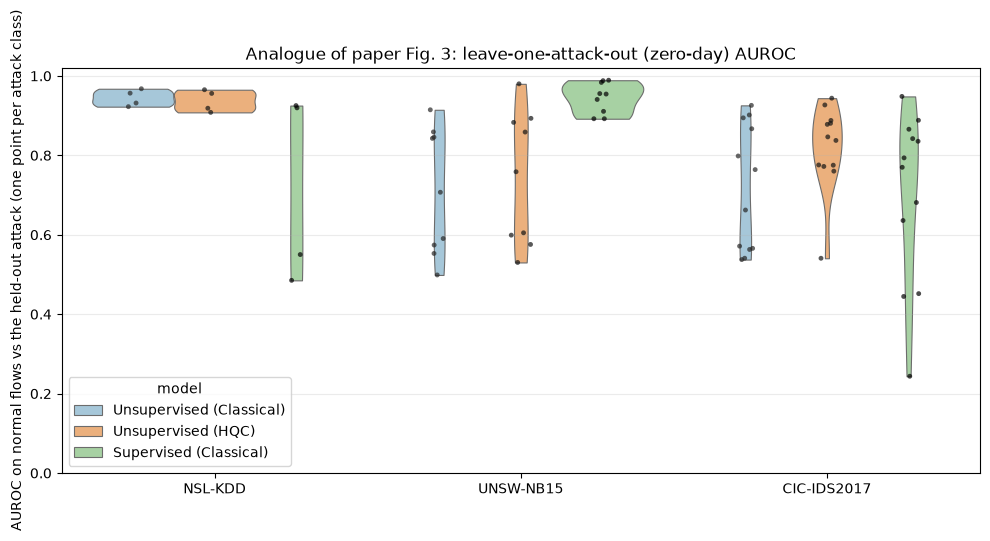

model                                 Supervised (Classical)  Unsupervised (Classical)  Unsupervised (HQC)
dataset     cls                                                                                           
CIC-IDS2017 Bot                                        0.636                     0.541               0.775
            DDoS                                       0.948                     0.764               0.772
            DoS GoldenEye                              0.888                     0.894               0.776
            DoS Hulk                                   0.866                     0.867               0.838
            DoS Slowhttptest                           0.445                     0.926               0.927
            DoS slowloris                              0.452                     0.798               0.878
            FTP-Patator                                0.835                     0.662               0.760
            Infiltration             

In [20]:
fig, ax = plt.subplots(figsize=(10, 4.8))
order = ["Unsupervised (Classical)", "Unsupervised (HQC)", "Supervised (Classical)"]
sns.violinplot(data=per_class, x="dataset", y="auroc", hue="model", hue_order=order, order=USE_DATASETS, cut=0, inner=None, linewidth=0.8,
               palette={"Unsupervised (Classical)": "#9ecae1", "Unsupervised (HQC)": "#fdae6b", "Supervised (Classical)": "#a1d99b"}, ax=ax)
sns.stripplot(data=per_class, x="dataset", y="auroc", hue="model", hue_order=order, order=USE_DATASETS, dodge=True, size=3.5, color="k", alpha=0.7, legend=False, ax=ax)
ax.set_ylabel("AUROC on normal flows vs the held-out attack (one point per attack class)"); ax.set_xlabel("")
ax.set_title("Analogue of paper Fig. 3: leave-one-attack-out (zero-day) AUROC"); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()
print(per_class.pivot_table(index=["dataset", "cls"], columns="model", values="auroc").round(3).to_string())

## 6. Which design choices matter? (paper Section 4.3, Tables 5 and 6)

All 16 x 2 hybrid (architecture, detector) combinations of all datasets and seeds are pooled. For every factor, runs that differ **only** in that factor (same dataset, same seed, same other four factors) are paired and compared with a paired t-test; `delta` is "condition 1 minus condition 2". The five factors are the detection mechanism, the variational objective, the latent regularisation, the QLayer placement and the QLayer read-out. The mean +- std columns pool all datasets, so the std (about 0.09 in the paper) mostly reflects the difference between datasets and architectures, not seed noise. Table 6 crosses placement and read-out.

In [21]:
hq = res[res.family == "HQC"].copy()
hq["variational"] = np.where(hq.vae, "VAE", "Standard AE"); hq["latreg"] = np.where(hq.reg, "With regularization", "Without regularization")
hq["placement"] = hq.place.str.capitalize(); hq["measure"] = np.where(hq.meas == "expval", "Expectation value", "Probabilities")
hq["mechanism"] = np.where(hq.detector == "recon", "Recon. error thresholding", "Downstream model (IF)")
FACTORS = [("Detection mechanism", "mechanism", "Recon. error thresholding", "Downstream model (IF)"),
           ("Variational objective", "variational", "Standard AE", "VAE"),
           ("Latent regularization", "latreg", "Without regularization", "With regularization"),
           ("QLayer placement", "placement", "Early", "Late"),
           ("QLayer measurement", "measure", "Expectation value", "Probabilities")]
keys = ["mechanism", "variational", "latreg", "placement", "measure"]
rows = []
for title, col, a_lab, b_lab in FACTORS:
    others = [k for k in keys if k != col] + ["dataset", "seed"]
    A = hq[hq[col] == a_lab].set_index(others)["auroc"].sort_index(); Bv = hq[hq[col] == b_lab].set_index(others)["auroc"].sort_index()
    A, Bv = A.align(Bv, join="inner")                                      # matched runs: every other factor, dataset and seed identical
    st = paired_stats(A.values, Bv.values)
    rows.append(dict(factor=title, cond_1=a_lab, auroc_1=f"{A.mean():.4f} +- {A.std():.4f}", cond_2=b_lab, auroc_2=f"{Bv.mean():.4f} +- {Bv.std():.4f}",
                     delta=st["delta"], ci99=f"[{st['ci_lo']:.4f}, {st['ci_hi']:.4f}]", p=st["p"], dz=st["dz"], significant=st["sig"], n_pairs=st["n"]))
T5 = pd.DataFrame(rows)
print("Table 5 analogue: paired t-tests over matched runs (delta = condition 1 - condition 2; significance level 0.01)")
display(T5.round(4))
T6 = hq.pivot_table(index="placement", columns="measure", values="auroc", aggfunc=lambda s: f"{s.mean():.4f} +- {s.std():.4f}")
print("Table 6 analogue: mean AUROC for placement x measurement")
display(T6)

Table 5 analogue: paired t-tests over matched runs (delta = condition 1 - condition 2; significance level 0.01)


,factor,cond_1,auroc_1,cond_2,auroc_2,delta,ci99,p,dz,significant,n_pairs
0,Detection mechanism,Recon. error thresholding,0.7583 +- 0.1191,Downstream model (IF),0.7797 +- 0.1099,-0.0214,"[-0.0389, -0.0040]",0.0017,-0.3293,True,96
1,Variational objective,Standard AE,0.7753 +- 0.1106,VAE,0.7627 +- 0.1191,0.0127,"[-0.0025, 0.0278]",0.0301,0.2247,False,96
2,Latent regularization,Without regularization,0.7666 +- 0.1126,With regularization,0.7714 +- 0.1175,-0.0049,"[-0.0195, 0.0098]",0.3858,-0.0889,False,96
3,QLayer placement,Early,0.7566 +- 0.1167,Late,0.7815 +- 0.1120,-0.0249,"[-0.0401, -0.0097]",0.0000,-0.4404,True,96
4,QLayer measurement,Expectation value,0.7656 +- 0.1131,Probabilities,0.7724 +- 0.1169,-0.0069,"[-0.0201, 0.0064]",0.1774,-0.1387,False,96


Table 6 analogue: mean AUROC for placement x measurement


measure,Expectation value,Probabilities
placement,,
Early,0.7563 +- 0.1132,0.7568 +- 0.1214
Late,0.7748 +- 0.1135,0.7881 +- 0.1114


## 7. The latent space of an autoencoder and of a variational autoencoder (paper Fig. 4)

The paper shows UMAP pictures of the latent space on the NSL-KDD test set: the variational constraint makes normal and attack codes overlap more. UMAP is not installed here, so t-SNE of the 8-dimensional latent means is used instead. Points are real NSL-KDD test flows coloured by ground-truth family, for the best hybrid architecture of NSL-KDD without (a) and with (b) the KL term.

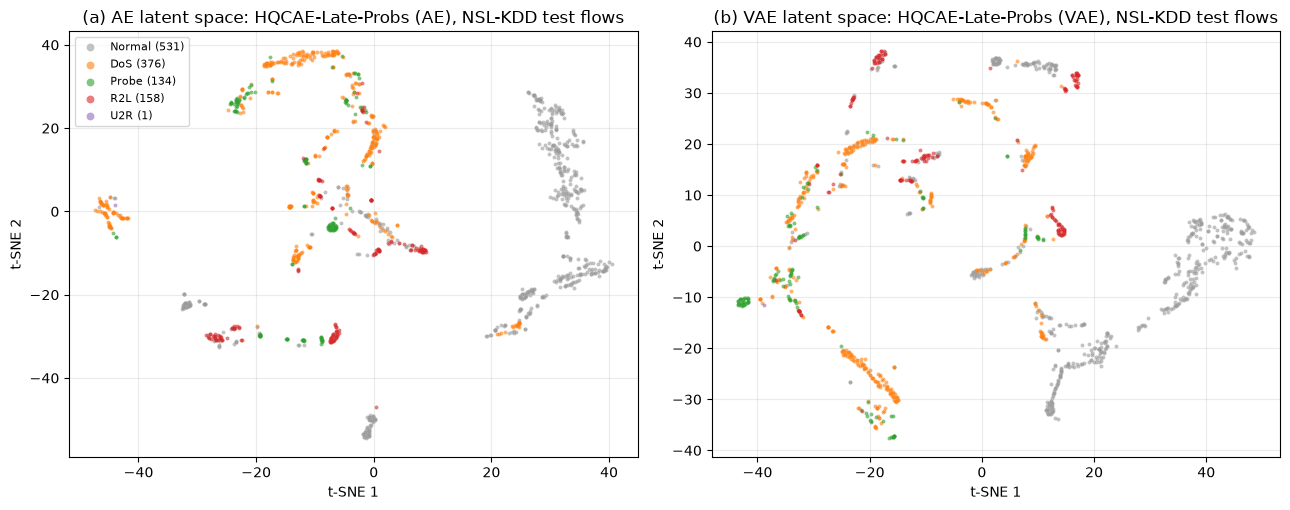

In [22]:
# Analogue of paper Fig. 4 (the paper uses UMAP, which is not installed here: t-SNE is used instead, CHOICE)
name = "NSL-KDD" if "NSL-KDD" in DS else USE_DATASETS[0]
d = DS[name]; hq_cfg = BEST[(name, "HQC")][0]; seed = SEEDS[0]
cfg_ae, cfg_vae = (hq_cfg[0], hq_cfg[1], False, False), (hq_cfg[0], hq_cfg[1], True, False)
rs = np.random.default_rng(SEED); sel = rs.choice(len(d["Xte"]), min(B["tsne_n"], len(d["Xte"])), replace=False)
Xs_t = torch.tensor(d["Xte"][sel]); gs = d["gte"][sel]
classes = ["Normal"] + sorted(set(gs) - {"Normal"})
pal = {c: ("#9a9a9a" if c == "Normal" else plt.cm.tab10(i)) for i, c in enumerate(classes)}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, cfg, title in zip(axes, (cfg_ae, cfg_vae), ("(a) AE latent space", "(b) VAE latent space")):
    if (name, cfg, seed) not in MODELS:
        ax.set_title(title + " (not trained)"); continue
    m = load_model(name, cfg, seed); _, z = recon_and_latent(m, Xs_t)
    emb = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(z)
    for c in classes:
        mk = gs == c
        ax.scatter(emb[mk, 0], emb[mk, 1], s=8, alpha=0.6, color=pal[c], label=f"{c} ({int(mk.sum())})", linewidths=0)
    ax.set_title(f"{title}: {cfg_name(cfg)}, {name} test flows"); ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
axes[0].legend(fontsize=8, markerscale=2)
plt.tight_layout(); plt.show()

## 8. Robustness to coherent gate noise (paper Section 3.7 and 4.4, Fig. 5)

The paper models hardware imperfection as a random over-rotation: after **every gate** of the variational circuit a gate `RX(eps)` with `eps ~ N(0, sigma^2)` is applied. For a single-qubit gate this corresponds to an average infidelity `r(sigma) = (1 - exp(-sigma^2/2)) / 3`, so `sigma` = 0.07-0.09 is today's superconducting hardware (`r` about 0.1 %) and `sigma` = 0.01 a logical-qubit regime (`r` about 1.7e-5). The equality of the noisy fast simulator with a PennyLane circuit that contains real `RX(eps)` gates was asserted in the circuit section. Here the best hybrid architecture on UNSW-NB15 is trained without noise and evaluated for the six noise levels of the paper; the dashed line is the best classical model.

noise study on UNSW-NB15, architecture HQCAE-Late-Probs (VAE, LatReg) [iforest], 2 trained models, sigmas [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]


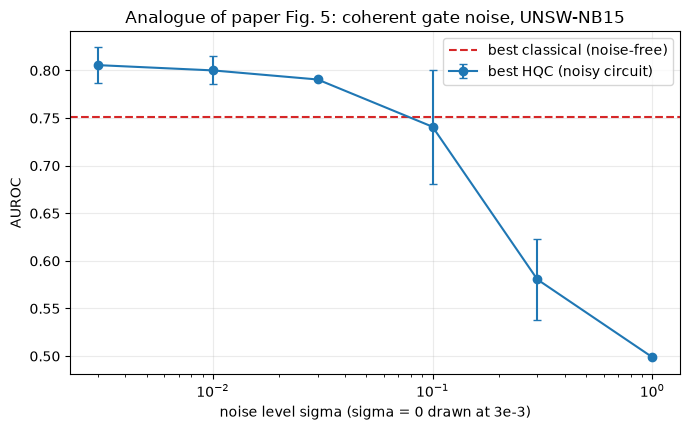

,mean,std,infidelity r(sigma),drop vs sigma=0 (%)
sigma,,,,
0.00,0.8056,0.0191,0.0000,0.0000
0.01,0.8001,0.0147,0.0000,0.6877
0.03,0.7905,0.0001,0.0001,1.8734
0.10,0.7409,0.0596,0.0017,8.0374
0.30,0.5805,0.0424,0.0147,27.9495
1.00,0.4988,0.0014,0.1312,38.0799


In [23]:
# Hardware-noise study (paper Section 3.7 / Fig. 5): coherent over-rotation RX(eps), eps ~ N(0, sigma^2), after every gate of the variational circuit,
# on the best hybrid architecture of UNSW-NB15. CHOICE: the model is trained without noise and evaluated with noise; every test flow sees its own noise draw.
nname = "UNSW-NB15" if "UNSW-NB15" in DS else USE_DATASETS[0]
d = DS[nname]; uni = d["uni_te"]; Xte_t = torch.tensor(d["Xte"][uni]); yte = d["yte"][uni]
ncfg, ndet = BEST[(nname, "HQC")]
print(f"noise study on {nname}, architecture {cfg_name(ncfg)} [{ndet}], {B['noise_seeds']} trained models, sigmas {SIGMAS}")
nrows = []
for seed in SEEDS[:B["noise_seeds"]]:
    m = load_model(nname, ncfg, seed); Xn_t = torch.tensor(normal_subset(d, seed))
    for sg in SIGMAS:
        gen = torch.Generator().manual_seed(seed * 7 + int(sg * 1000))
        err, z = recon_and_latent(m, Xte_t, eps_sigma=sg, gen=gen)
        if ndet == "recon":
            s = err
        else:
            _, z_tr = recon_and_latent(m, Xn_t[:B["ifor_cap"]])             # forest fitted on the NOISE-FREE latent codes of the normal training flows
            s = -IsolationForest(n_estimators=100, random_state=seed).fit(z_tr).score_samples(z)
        nrows.append(dict(seed=seed, sigma=sg, auroc=roc_auc_score(yte, s)))
noise = pd.DataFrame(nrows)
nsum = noise.groupby("sigma")["auroc"].agg(["mean", "std"])
best_cls_unsw = res[(res.dataset == nname) & (res.cfg == BEST[(nname, "Classical")][0]) & (res.detector == BEST[(nname, "Classical")][1])]["auroc"].mean()
fig, ax = plt.subplots(figsize=(7, 4.4))
xs = np.array([max(s, 3e-3) for s in nsum.index])                            # sigma = 0 is drawn at 3e-3 on the log axis
ax.errorbar(xs, nsum["mean"], yerr=nsum["std"].fillna(0), marker="o", capsize=3, label="best HQC (noisy circuit)")
ax.axhline(best_cls_unsw, color="tab:red", ls="--", label="best classical (noise-free)")
ax.set_xscale("log"); ax.set_xlabel("noise level sigma (sigma = 0 drawn at 3e-3)"); ax.set_ylabel("AUROC")
ax.set_title(f"Analogue of paper Fig. 5: coherent gate noise, {nname}"); ax.legend(); plt.tight_layout(); plt.show()
nsum["infidelity r(sigma)"] = (1 - np.exp(-nsum.index.values ** 2 / 2)) / 3
nsum["drop vs sigma=0 (%)"] = 100 * (nsum["mean"].iloc[0] - nsum["mean"]) / nsum["mean"].iloc[0]
nsum.round(4)

## 9. The paper's numbers next to this notebook's numbers

Every checkable number or qualitative claim of the paper's Results section is listed with the value measured here and a verdict. "Reproduced" means within 0.02 AUROC of the paper's mean (numbers) or the same direction and the same significance verdict (comparisons). "Not reached" / "exceeded" give the gap. Claims that need more seeds than the chosen mode provides (a paired t-test needs at least 3) or that the notebook cannot test say "cannot be checked".

In [24]:
TOL = 0.02                                          # "reproduced" = within 0.02 AUROC of the paper's mean
PAPER = {  # (table, row, dataset) -> paper value
    ("T2", "Classical best"): {"UNSW-NB15": 0.8976, "NSL-KDD": 0.9595, "CIC-IDS2017": 0.9424},
    ("T2", "HQC best"):       {"UNSW-NB15": 0.9009, "NSL-KDD": 0.9611, "CIC-IDS2017": 0.9361},
    ("T4 full", "Supervised (Classical)"): {"UNSW-NB15": 0.9717, "NSL-KDD": 0.8828, "CIC-IDS2017": 0.9991},
    ("T4 LOAO", "Supervised (Classical)"):   {"UNSW-NB15": 0.9346, "NSL-KDD": 0.7596, "CIC-IDS2017": 0.8499},
    ("T4 LOAO", "Unsupervised (Classical)"): {"UNSW-NB15": 0.8326, "NSL-KDD": 0.9448, "CIC-IDS2017": 0.8462},
    ("T4 LOAO", "Unsupervised (HQC)"):       {"UNSW-NB15": 0.8449, "NSL-KDD": 0.9486, "CIC-IDS2017": 0.8488},
}
PAPER_LOAO_STD = {"Supervised (Classical)": {"UNSW-NB15": 0.0665, "NSL-KDD": 0.2706, "CIC-IDS2017": 0.1935},
                  "Unsupervised (Classical)": {"UNSW-NB15": 0.1645, "NSL-KDD": 0.0470, "CIC-IDS2017": 0.1383},
                  "Unsupervised (HQC)": {"UNSW-NB15": 0.1406, "NSL-KDD": 0.0424, "CIC-IDS2017": 0.1321}}

def verdict(nb, paper, tol=TOL):
    gap = nb - paper
    if abs(gap) <= tol: return "reproduced", gap
    return ("exceeded" if gap > 0 else "not reached"), gap

claims = []
def add(claim, paper, nb, verd):
    claims.append(dict(claim=claim, paper=paper, notebook=nb, verdict=verd))

def num_row(claim, paper_v, nb_v):
    v, gap = verdict(nb_v, paper_v)
    add(claim, f"{paper_v:.4f}", f"{nb_v:.4f} (gap {gap:+.4f})", v if v == "reproduced" else f"{v} by {abs(gap):.3f}")

t2 = T2.set_index("dataset")
for name in USE_DATASETS:
    num_row(f"{name}: best classical AE, full-test AUROC (Table 2)", PAPER[("T2", "Classical best")][name], t2.loc[name, "_c"])
    num_row(f"{name}: best HQC AE, full-test AUROC (Table 2)", PAPER[("T2", "HQC best")][name], t2.loc[name, "_h"])
    # direction of the HQC - classical difference and its significance
    pd_delta = PAPER[("T2", "HQC best")][name] - PAPER[("T2", "Classical best")][name]
    nb_delta, sig = t2.loc[name, "d_auroc"], t2.loc[name, "significant"]
    paper_sig = {"UNSW-NB15": "not significant", "NSL-KDD": "not significant", "CIC-IDS2017": "significant (classical better)"}[name]
    nb_sig = "cannot be tested (< 3 seeds)" if sig is None else ("significant" if sig else "not significant")
    same_sign = np.sign(nb_delta) == np.sign(pd_delta)
    if sig is None:
        verd = "sign reproduced; significance cannot be tested (< 3 seeds)" if same_sign else "not reproduced (sign differs)"
    elif same_sign:
        verd = "reproduced" if paper_sig.startswith("significant") == bool(sig) else "sign reproduced, significance differs"
    else:
        verd = "not reproduced (sign differs)"
    if abs(nb_delta) < 0.005 and abs(pd_delta) < 0.005 and not (sig and not paper_sig.startswith("significant")):
        verd = "consistent (both differences negligible, < 0.005)" if not same_sign else verd
    add(f"{name}: HQC - classical difference (Table 2)", f"{pd_delta:+.4f}, {paper_sig}", f"{nb_delta:+.4f}, {nb_sig}", verd)
for name in USE_DATASETS:
    s_full = sup[(sup.dataset == name) & (sup.model == "Supervised NN (classical encoder)")]["auroc"].mean()
    num_row(f"{name}: supervised classical, full test (Table 4)", PAPER[("T4 full", "Supervised (Classical)")][name], s_full)
    for model in ("Supervised (Classical)", "Unsupervised (Classical)", "Unsupervised (HQC)"):
        v = T4[(T4.protocol == "LOAO") & (T4.model == model) & (T4.dataset == name)]["auroc_mean"].iloc[0]
        num_row(f"{name}: {model}, LOAO mean AUROC (Table 4)", PAPER[("T4 LOAO", model)][name], v)
# Observation 2: HQC LOAO mean >= classical and a tighter spread
for name in USE_DATASETS:
    g = T4[(T4.protocol == "LOAO") & (T4.dataset == name)].set_index("model")
    h, c = g.loc["Unsupervised (HQC)"], g.loc["Unsupervised (Classical)"]
    add(f"{name}: LOAO, HQC higher mean and lower std than classical unsupervised (Observation 2)", "yes (all 3 datasets)",
        f"mean {h.auroc_mean:.4f} vs {c.auroc_mean:.4f}; std {h.auroc_std:.4f} vs {c.auroc_std:.4f}",
        "reproduced" if (h.auroc_mean > c.auroc_mean and h.auroc_std < c.auroc_std) else "not reproduced")
    s = g.loc["Supervised (Classical)"]
    add(f"{name}: LOAO std of the supervised model larger than that of the unsupervised ones", "yes (0.0665-0.2706 vs 0.04-0.16)" if name != "UNSW-NB15" else "no (0.0665 < 0.14-0.16)",
        f"{s.auroc_std:.4f} vs {c.auroc_std:.4f} / {h.auroc_std:.4f}", "reproduced" if ((s.auroc_std > c.auroc_std) == (name != "UNSW-NB15")) else "not reproduced")
# Table 5 design factors: direction and significance
PAPER5 = {"Detection mechanism": (0.0759, True), "Variational objective": (0.0221, True), "Latent regularization": (0.0045, False),
          "QLayer placement": (0.0133, True), "QLayer measurement": (-0.0010, False)}
for _, r in T5.iterrows():
    pdl, psig = PAPER5[r.factor]
    sig = r.significant
    sign_ok = np.sign(r.delta) == np.sign(pdl)
    if sig is None:
        verd = "sign reproduced; significance cannot be tested (< 3 seeds)" if sign_ok else "not reproduced (sign)"
    else:
        verd = "reproduced" if (sign_ok and bool(sig) == psig) else ("sign reproduced, significance differs" if sign_ok else "not reproduced")
    add(f"{r.factor}: {r.cond_1} - {r.cond_2} (Table 5)", f"{pdl:+.4f}, {'significant' if psig else 'not significant'}",
        f"{r.delta:+.4f}, {'n/a' if sig is None else ('significant' if sig else 'not significant')} (p={r.p:.3g})" if not np.isnan(r.p) else f"{r.delta:+.4f}, n/a", verd)
# Table 6 cell means
P6 = {("Early", "Expectation value"): 0.8709, ("Early", "Probabilities"): 0.8750, ("Late", "Expectation value"): 0.8607, ("Late", "Probabilities"): 0.8586}
for (pl, me), pv in P6.items():
    nbv = hq[(hq.placement == pl) & (hq.measure == me)]["auroc"].mean()
    num_row(f"mean AUROC, {pl} placement x {me} (Table 6)", pv, nbv)
# Fig. 5: noise
n0 = nsum.loc[0.0, "mean"]; n01 = nsum.loc[0.01, "mean"]; drop01 = 100 * (n0 - n01) / n0
add("noise sigma=0.01: relative AUROC drop (Fig. 5 / Section 4.4)", "-2.68 %", f"-{drop01:.2f} %", "reproduced" if abs(drop01 - 2.68) <= 1.0 else ("not reached (smaller drop)" if drop01 < 2.68 else "exceeded (larger drop)"))
add("noise sigma=0.01: HQC falls below the best classical model (Fig. 5)", "yes", f"HQC {n01:.4f} vs classical {best_cls_unsw:.4f}", "reproduced" if n01 < best_cls_unsw else "not reproduced")
add("AUROC decreases monotonically with the noise level (Fig. 5)", "yes", " > ".join(f"{v:.3f}" for v in nsum["mean"].values),
    "reproduced" if np.all(np.diff(nsum["mean"].values) <= 1e-3) else "not reproduced")
add("architecture sensitivity: spread of HQC configurations larger than classical (Observation 1 / Fig. 2)", "yes",
    " ; ".join(f"{n}: HQC std {cfg_mean[(cfg_mean.dataset==n)&(cfg_mean.family=='HQC')]['auroc'].std():.3f} vs classical {cfg_mean[(cfg_mean.dataset==n)&(cfg_mean.family=='Classical')]['auroc'].std():.3f}" for n in USE_DATASETS),
    "reproduced" if all(cfg_mean[(cfg_mean.dataset==n)&(cfg_mean.family=='HQC')]['auroc'].std() > cfg_mean[(cfg_mean.dataset==n)&(cfg_mean.family=='Classical')]['auroc'].std() for n in USE_DATASETS) else "not reproduced")
add("hybrid models on real quantum hardware", "not run in the paper (simulation only)", "not run", "cannot be checked")
CL = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 110, "display.width", 250)
print("verdict summary:")
print(CL["verdict"].str.replace(r" by .*$|[;,(].*$", "", regex=True).str.strip().value_counts().to_string())
CL

verdict summary:
verdict
not reached          16
reproduced           13
not reproduced        8
sign reproduced       2
consistent            1
cannot be checked     1


,claim,paper,notebook,verdict
0,"NSL-KDD: best classical AE, full-test AUROC (Table 2)",0.9595,0.9509 (gap -0.0086),reproduced
1,"NSL-KDD: best HQC AE, full-test AUROC (Table 2)",0.9611,0.9504 (gap -0.0107),reproduced
2,NSL-KDD: HQC - classical difference (Table 2),"+0.0016, not significant","-0.0005, cannot be tested (< 3 seeds)","consistent (both differences negligible, < 0.005)"
3,"UNSW-NB15: best classical AE, full-test AUROC (Table 2)",0.8976,0.7512 (gap -0.1464),not reached by 0.146
4,"UNSW-NB15: best HQC AE, full-test AUROC (Table 2)",0.9009,0.8056 (gap -0.0953),not reached by 0.095
5,UNSW-NB15: HQC - classical difference (Table 2),"+0.0033, not significant","+0.0544, cannot be tested (< 3 seeds)",sign reproduced; significance cannot be tested (< 3 seeds)
6,"CIC-IDS2017: best classical AE, full-test AUROC (Table 2)",0.9424,0.7473 (gap -0.1951),not reached by 0.195
7,"CIC-IDS2017: best HQC AE, full-test AUROC (Table 2)",0.9361,0.8499 (gap -0.0862),not reached by 0.086
8,CIC-IDS2017: HQC - classical difference (Table 2),"-0.0063, significant (classical better)","+0.1027, cannot be tested (< 3 seeds)",not reproduced (sign differs)
9,"NSL-KDD: supervised classical, full test (Table 4)",0.8828,0.8903 (gap +0.0075),reproduced


## Reading the paper critically

All numbers below refer to the stored `FAST_MODE = True` run (2 seeds, 2,000 normal training flows per run, at most 8 epochs, part of each test set). They are a small-scale check, not a replication at the paper's scale.

**What this run supports.**
* **NSL-KDD is reproduced in level and in story.** Best classical and best hybrid autoencoders reach about 0.95 AUROC (paper 0.9595 and 0.9611), the supervised network 0.89 (paper 0.8828), and under leave-one-attack-out the unsupervised models stay above 0.9 on every attack family while the supervised network collapses on R2L and U2R (about 0.5), exactly the instability the paper highlights. On this dataset the hybrid model is not better than the classical one (difference of -0.0005, negligible).
* **The supervised references are close to the paper** on UNSW-NB15 (0.975 vs 0.972; LOAO 0.945 vs 0.935), so the preprocessing and the splits are not the reason for the gaps below.
* **Noise.** AUROC decreases monotonically with the gate-noise level and reaches chance level (about 0.5) at `sigma = 1`, as in Fig. 5.

**What this run does not support, and why that is not evidence against the paper.**
* On UNSW-NB15 and CIC-IDS2017 every unsupervised model is far below the paper (classical 0.75 and 0.75 vs 0.90 and 0.94). Even a plain PCA reconstruction detector beats the best classical autoencoder on CIC-IDS2017 (0.81 vs 0.75), which points at under-training (2,000 flows, at most 8 epochs, heavy-tailed features that are only standardised) rather than at the method.
* The paper's design-factor results are **not reproduced** (reconstruction error vs Isolation Forest, early vs late placement have the opposite sign here). The paper's own effects are 0.01-0.08 AUROC; with undertrained autoencoders, whose reconstruction error is a poor score, and only two seeds these differences cannot be resolved. A paired t-test over seeds is also impossible with two seeds, so the significance verdicts of Table 2 are marked "cannot be tested".
* The apparent hybrid advantage on UNSW-NB15 (+0.054) and CIC-IDS2017 (+0.103) must **not** be read as a quantum advantage: both "best" entries use the Isolation Forest detector, whose AUROC varies strongly between configurations (std 0.05-0.07), and the "best of 32 hybrid configurations" is compared with the "best of 8 classical ones", both selected on the test AUROC. Taking a maximum over four times as many noisy candidates favours the larger family even if nothing differs. The paper uses the same selection rule.
* The claim that hybrid models have a larger spread over architectures (Observation 1) is not visible here, and the LOAO claim (Observation 2) holds on CIC-IDS2017 only.

**Things worth questioning in the paper's design.**
1. **The quantum layer is tiny.** With 4 qubits and 2 layers it has 24 trainable angles inside a network of roughly 11,000-18,000 parameters, so its influence on the result is hard to separate from the classical layers around it (Exercise 2). In the early/ExpVal variant the quantum read-out is a 4-number bottleneck.
2. **"Best configuration" is chosen on test data** and then compared with a paired t-test; the p-values describe seeds, not the choice among 40 configurations.
3. **Circuit cost.** In the simulator amplitude embedding is one operation (depth 9 for the whole circuit); compiled to one- and two-qubit gates it makes the early variants about six times deeper (depth 57 against 9 for the late variants, see the circuit section). The accuracy advantage of early placement claimed in the paper would have to be paid for on hardware.
4. **Noise model.** Coherent `RX(eps)` errors drawn independently per flow, a model that is trained without noise, and exact (shot-free) readout are all choices; the paper does not say which it used. Here the drop at `sigma = 0.01` is only 0.7 % instead of the paper's 2.7 %, so the paper's conclusion that even `sigma = 0.01` removes the hybrid advantage is sensitive to those details.
5. **Datasets.** NSL-KDD's test set contains attack types absent from training, so its "full test" is already partly zero-day; CIC-IDS2017 is known to contain label errors and, with a random 5 % / 95 % flow-level split, consecutive flows of the same traffic generator can land in both splits. The paper's contamination argument applies to all three.
6. **No hardware.** Everything is simulation; the practical viability claims rest on the noise model alone.

## Exercises

1. **Qubits and layers.** Change `N_QUBITS` to 3 and 5 and `N_LAYERS` to 1 and 3 in the config cell (the early placement then projects to 8 or 32 numbers). Does the early/late ranking of the previous tables survive? Plot the AUROC of the best hybrid configuration against the number of trainable quantum angles.
2. **Is the quantum layer doing anything?** Replace the QLayer by a classical layer with the same input and output sizes (for the early/ExpVal variant: `Linear(16, 4)` followed by `tanh`) and rerun a single seed on one dataset. Is the classical replacement within the seed-to-seed spread of the hybrid model? What would you need to see before attributing a gain to the quantum circuit?
3. **Selection on the test set.** The "best configuration" is picked by its test AUROC, as in the paper. Hold out a validation split of the training data (it contains attacks in NSL-KDD and UNSW-NB15 but you may use only normal flows plus a handful of labelled attacks) and select the configuration there instead. How much do the "best" AUROCs of Table 2 shrink?
4. **Noise-aware training.** In the noise study the models are trained without noise. Train the best hybrid model with the noise injected during training (pass `eps` in `train_ae`) at `sigma = 0.03` and re-evaluate the six noise levels. Is the degradation of Fig. 5 reduced, and does the noisy model still beat the best classical one?
5. **Hardware-like noise.** Replace the coherent `RX(eps)` model by depolarising noise (a `qml.DepolarizingChannel` after each gate on `default.mixed`) with the same average gate infidelity `r(sigma)` and compare the AUROC curves. Which noise model is more damaging at equal infidelity, and why does the paper's coherent model make the circuit-level error scale with `sigma` rather than `sigma^2`?